# Samuel: DQN hyperparameter experiments

Do not change train.py here. All experiments must use our current main branch.

# 1. Setup

In [1]:
import os
import shutil
import subprocess
import sys
from pathlib import Path

os.environ["PATH"] = str(Path.home() / ".local/bin") + os.pathsep + os.environ["PATH"]
if shutil.which("uv") is None:
    raise RuntimeError("Install uv locally, then restart the notebook kernel. On macOS: brew install uv")
subprocess.run(["uv", "--version"], check=True)


uv 0.13.7 (Homebrew 2026-11-03 aarch64-apple-darwin)


CompletedProcess(args=['uv', '--version'], returncode=0)

In [2]:
import json
import hashlib
from datetime import datetime, timezone

REPO = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "train.py").is_file() and (p / "pyproject.toml").is_file()), None)
if REPO is None:
    raise RuntimeError("Open the notebook inside your Deep-Q-Learning project.")
os.chdir(REPO)
os.environ["UV_PROJECT_ENVIRONMENT"] = str(REPO / ".venv")
# Use the project environment for uv commands (avoids a harmless VIRTUAL_ENV mismatch warning).
os.environ.pop("VIRTUAL_ENV", None)
# Keep local runtimes and caches outside system temporary storage.
os.environ["UV_CACHE_DIR"] = str(REPO / ".samuel-runtime/cache")
os.environ["UV_PYTHON_INSTALL_DIR"] = str(REPO / ".samuel-runtime/python")
# Use the current checkout without switching branches, pulling or cloning.
subprocess.run(["uv", "sync", "--locked"], check=True)

RUN_ID = "notebook_batch_epsilon_01"  # Keep this ID when restoring a session; change for a new study.
RUN_EXPERIMENTS = list(range(1, 11))  # e.g. [1, 2, 3, 4], then [5, 6, 7], then [8, 9, 10]
TOTAL_STEPS = 1_000_000
MEMBER = f"Samuel/{RUN_ID}"
OUTPUT = REPO / f"Samuel_outputs_{RUN_ID}"
OUTPUT.mkdir(exist_ok=True)
COMMIT = subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip()
print("Source commit:", COMMIT, "Output:", OUTPUT)
print("Requested training budget:", len(RUN_EXPERIMENTS) * TOTAL_STEPS)

# auto prefers CUDA, then Apple MPS, then CPU. You can explicitly choose one.
DEVICE = "auto"
THREADS = 2
os.environ["SAMUEL_DEVICE"] = DEVICE
os.environ["SAMUEL_THREADS"] = str(THREADS)
os.environ["OMP_NUM_THREADS"] = str(THREADS)
os.environ["MKL_NUM_THREADS"] = str(THREADS)
DEVICE_BOOTSTRAP = 'import os\nimport torch\nimport train\nrequested = os.environ.get("SAMUEL_DEVICE", "auto")\nchosen = ("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu") if requested == "auto" else requested\nif chosen == "cuda" and not torch.cuda.is_available(): raise RuntimeError("CUDA is unavailable")\nif chosen == "mps" and not torch.backends.mps.is_available(): raise RuntimeError("Apple MPS is unavailable")\ntrain.DEVICE = torch.device(chosen)\ntorch.set_num_threads(int(os.environ.get("SAMUEL_THREADS", "2")))\nprint("Samuel device:", train.DEVICE, flush=True)\n'


Source commit: b09aa8fb96c24f14830507bbc93cf2d4bf57dffa Output: /Users/wiseking/ALU Projects/Deep-Q-Learning/Samuel_outputs_notebook_batch_epsilon_01
Requested training budget: 10000000


Resolved 51 packages in 5ms
Checked 26 packages in 4ms


### Environment and interface checks
The checks use the actual imported components, exercise one gradient update, and stop on failure before long training. The checks use your selected local CUDA, Apple MPS or CPU device. A new manifest records exact source hashes. Restored outputs must match this source revision.


In [3]:
preflight = r"""
import argparse
import numpy as np
import torch
import train
env = train.make_env()
try:
    obs, _ = env.reset(seed=0)
    obs = np.asarray(obs)
    assert obs.shape == (4,84,84) and obs.dtype == np.uint8
    online, target = train.create_networks(env.action_space.n)
    assert online(torch.as_tensor(obs, device=train.DEVICE).unsqueeze(0)).shape == (1, env.action_space.n)
    buffer = train.ReplayBuffer(8)
    nxt, reward, terminated, truncated, _ = env.step(0)
    for _ in range(8): buffer.push(obs, 0, reward, np.asarray(nxt), terminated)
    optimizer = torch.optim.Adam(online.parameters(), lr=1e-4, eps=1.5e-4)
    loss = train.train_step(online, target, optimizer, buffer.sample(8), .99)
    assert np.isfinite(loss)
    train.sync_target(online, target)
    print('PASS: environment, CNN, replay, gradient update and target synchronization; device', train.DEVICE)
finally:
    env.close()
"""
subprocess.run(["uv", "run", "python", "-c", DEVICE_BOOTSTRAP + "\n" + preflight], check=True)
manifest = {
    "run_id": RUN_ID, "source_commit": COMMIT, "steps_per_experiment": TOTAL_STEPS,
    "source_sha256": {p: hashlib.sha256((REPO / p).read_bytes()).hexdigest() for p in ["train.py", "plot_results.py"]},
    "device_requested": DEVICE, "threads": THREADS,
    "created_utc": datetime.now(timezone.utc).isoformat(),
}
manifest_path = OUTPUT / "manifest.json"
if manifest_path.exists():
    previous = json.loads(manifest_path.read_text())
    assert previous["source_commit"] == COMMIT and previous["source_sha256"] == manifest["source_sha256"], "Source changed: use a fresh RUN_ID."
else:
    manifest_path.write_text(json.dumps(manifest, indent=2))


Samuel device: mps


A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


PASS: environment, CNN, replay, gradient update and target synchronization; device mps


### Evaluation helper
Each completed final checkpoint is evaluated greedily on five fixed selection seeds (100–104). Only normally terminated games qualify for selection. The final selected model is tested separately on 20 seeds (1000–1019). A step cap is reported, never counted as a win. This evaluates final weights from each run, not intermediate checkpoint selection.


In [4]:
EVALUATOR = OUTPUT / "evaluate_samuel.py"
EVALUATOR.write_text('import argparse, json\nfrom pathlib import Path\nimport numpy as np\nimport torch\nimport os\nimport torch\nimport train\nrequested = os.environ.get("SAMUEL_DEVICE", "auto")\nchosen = ("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu") if requested == "auto" else requested\nif chosen == "cuda" and not torch.cuda.is_available(): raise RuntimeError("CUDA is unavailable")\nif chosen == "mps" and not torch.backends.mps.is_available(): raise RuntimeError("Apple MPS is unavailable")\ntrain.DEVICE = torch.device(chosen)\ntorch.set_num_threads(int(os.environ.get("SAMUEL_THREADS", "2")))\nprint("Samuel device:", train.DEVICE, flush=True)\n\n\ndef evaluate(checkpoint, seeds, video=None, max_steps=27000):\n    env = train.make_env(render_mode="rgb_array" if video else None)\n    writer = None\n    episodes = []\n    try:\n        model = train.QNetwork(env.action_space.n).to(train.DEVICE)\n        model.load_state_dict(torch.load(checkpoint, map_location=train.DEVICE, weights_only=True))\n        assert all(torch.isfinite(p).all() for p in model.parameters())\n        model.eval()\n        for seed in seeds:\n            obs, _ = env.reset(seed=seed)\n            total = 0.0\n            terminated = truncated = False\n            for step in range(1, max_steps + 1):\n                if video:\n                    import cv2\n                    frame = env.render()\n                    if writer is None:\n                        writer = cv2.VideoWriter(str(video), cv2.VideoWriter_fourcc(*"mp4v"), 15, (frame.shape[1], frame.shape[0]))\n                        if not writer.isOpened(): raise RuntimeError("Cannot create MP4")\n                    writer.write(cv2.cvtColor(frame, cv2.COLOR_RGB2BGR))\n                with torch.inference_mode():\n                    q = model(torch.as_tensor(np.asarray(obs), device=train.DEVICE).unsqueeze(0))\n                    assert torch.isfinite(q).all()\n                    action = int(q.argmax(1).item())\n                obs, reward, terminated, truncated, _ = env.step(action)\n                total += float(reward)\n                if terminated or truncated: break\n            episodes.append(dict(seed=seed, reward=total, length=step, terminated=bool(terminated), truncated=bool(truncated), capped=not (terminated or truncated)))\n        rewards = [e["reward"] for e in episodes]\n        return dict(checkpoint=str(checkpoint), mean_reward=float(np.mean(rewards)), std_reward=float(np.std(rewards)), wins=sum(e["reward"] > 0 and e["terminated"] and not e["truncated"] and not e["capped"] for e in episodes), episodes=episodes)\n    finally:\n        if writer is not None: writer.release()\n        env.close()\n\nif __name__ == "__main__":\n    p = argparse.ArgumentParser()\n    p.add_argument("checkpoint"); p.add_argument("result")\n    p.add_argument("--episodes", type=int, default=5); p.add_argument("--seed", type=int, default=100)\n    p.add_argument("--video")\n    a = p.parse_args()\n    if Path(a.result).exists() or (a.video and Path(a.video).exists()): raise FileExistsError("Evaluation outputs already exist")\n    result = evaluate(a.checkpoint, range(a.seed, a.seed+a.episodes), a.video)\n    Path(a.result).write_text(json.dumps(result, indent=2))\n    print(json.dumps({k:v for k,v in result.items() if k != "episodes"}, indent=2))\n')
os.environ["PYTHONPATH"] = str(REPO) + os.pathsep + os.environ.get("PYTHONPATH", "")


In [5]:
import csv
import math

BASELINE = dict(learning_rate=1e-4, gamma=.99, batch_size=32,
                epsilon_start=1.0, epsilon_end=.01, epsilon_decay_steps=100000)
CHANGES = {1: {}, 2: {"batch_size": 8}, 3: {"batch_size": 16},
           4: {"batch_size": 64}, 5: {"batch_size": 128},
           6: {"batch_size": 64, "learning_rate": 2e-4},
           7: {"batch_size": 128, "learning_rate": 4e-4},
           8: {"epsilon_start": .5}, 9: {"epsilon_start": .75}}

def read_record(n):
    path = OUTPUT / f"experiment_{n}" / "record.json"
    if not path.exists(): raise RuntimeError(f"Experiment {n} is incomplete; run or restore it first.")
    return json.loads(path.read_text())

def choose_best(numbers):
    records = [read_record(n) for n in numbers]
    valid = [r for r in records if all(e["terminated"] and not e["truncated"] and not e["capped"] for e in r["evaluation"]["episodes"])]
    if not valid: raise RuntimeError("No fully terminated evaluation is eligible.")
    return max(valid, key=lambda r: (r["evaluation"]["mean_reward"], -r["experiment"]))

def run_experiment(n, changes):
    if n not in RUN_EXPERIMENTS:
        print(f"Experiment {n} skipped by RUN_EXPERIMENTS")
        return
    config = dict(BASELINE, **changes)
    folder = OUTPUT / f"experiment_{n}"
    folder.mkdir(exist_ok=True)
    record_path = folder / "record.json"
    if record_path.exists():
        old = read_record(n)
        assert old["config"] == config and old["steps"] == TOTAL_STEPS
        assert hashlib.sha256((folder / "model.pth").read_bytes()).hexdigest() == old["model_sha256"]
        receipt_info = json.loads((folder / "training_complete.json").read_text())
        where = receipt_info.get("trained_on", "this computer")
        ev = old["evaluation"]
        print(f"Experiment {n} already completed (trained on {where}); keeping its measured result.")
        print(f"  Last-100 training mean {old['last100_training_mean']:+.2f}; "
              f"selection mean {ev['mean_reward']:+.2f} (std {ev['std_reward']:.2f}), {ev['wins']}/5 wins.")
        return
    checkpoint = REPO / "models" / MEMBER / f"experiment_{n}.pth"
    log = REPO / "logs" / MEMBER / f"experiment_{n}.csv"
    receipt = folder / "training_complete.json"
    if not receipt.exists():
        if checkpoint.exists() or log.exists():
            raise RuntimeError("Partial run exists. Use a fresh RUN_ID or restore a completed run; exact resume is unsupported.")
        cmd = ["uv", "run", "python", "-c", DEVICE_BOOTSTRAP + "\ntrain.main()", "--member", MEMBER, "--experiment", str(n),
               "--total_steps", str(TOTAL_STEPS), "--buffer_size", "50000",
               "--learning_starts", "10000", "--train_every", "1", "--target_update_every", "1000"]
        for key, value in config.items(): cmd += [f"--{key}", str(value)]
        print(" ".join(cmd), flush=True)
        with (folder / "training_console.log").open("a") as console:
            # Stream progress to the notebook and retain an exact console transcript.
            with subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1, env=dict(os.environ, PYTHONUNBUFFERED="1")) as process:
                for line in process.stdout:
                    print(line, end="", flush=True); console.write(line); console.flush()
                returncode = process.wait()
        if returncode: raise RuntimeError(f"Training failed ({returncode}); see {folder / 'training_console.log'}")
        if not checkpoint.exists() or not log.exists(): raise RuntimeError("Training returned without required artifacts")
        # A zero exit from the explicit million-step loop is the completion evidence;
        # the last CSV row may precede the final step because partial episodes aren't logged.
        shutil.copy2(checkpoint, folder / "model.pth")
        shutil.copy2(log, folder / "training.csv")
        receipt.write_text(json.dumps(dict(steps=TOTAL_STEPS, config=config, source_commit=COMMIT, returncode=0), indent=2))
    receipt_data = json.loads(receipt.read_text())
    assert receipt_data["steps"] == TOTAL_STEPS and receipt_data["config"] == config
    with (folder / "training.csv").open() as f: rows = list(csv.DictReader(f))
    assert rows and all(math.isfinite(float(r["loss"])) and math.isfinite(float(r["reward"])) for r in rows)
    result_path = folder / "selection_evaluation.json"
    if not result_path.exists():
        subprocess.run(["uv", "run", "python", str(EVALUATOR), str(folder / "model.pth"), str(result_path)], check=True)
    evaluation = json.loads(result_path.read_text())
    last100 = [float(r["reward"]) for r in rows[-100:]]
    record = dict(experiment=n, config=config, steps=TOTAL_STEPS, last_logged_step=int(rows[-1]["step"]),
                  completed_episodes=len(rows), last100_training_mean=sum(last100)/len(last100),
                  evaluation=evaluation, source_commit=COMMIT,
                  model_sha256=hashlib.sha256((folder / "model.pth").read_bytes()).hexdigest())
    record_path.write_text(json.dumps(record, indent=2))
    print(f"Experiment {n}: selection mean {evaluation['mean_reward']:+.2f}; last-100 training mean {record['last100_training_mean']:+.2f}")


# 2. Experiments
Every active cell below explicitly uses the common **1,000,000-step** setup. Baseline: learning rate 0.0001, gamma 0.99, batch 32, epsilon 1.0 → 0.01 over 100,000 steps; replay 50,000, warm-up 10,000, update every step, target sync every 1,000. Shared training seed: 0.

Use the same five-game greedy selection procedure for all runs. Experiments 6–7 change both learning rate and batch size; they do not isolate batch size alone. Selection differences from one training seed are preliminary.


### Experiment 1: Baseline


In [6]:
run_experiment(1, CHANGES[1])


Experiment 1 already completed (trained on this computer); keeping its measured result.
  Last-100 training mean +6.39; selection mean +10.20 (std 1.72), 5/5 wins.


### Experiment 2: Batch size 8


In [7]:
run_experiment(2, CHANGES[2])


Experiment 2 already completed (trained on this computer); keeping its measured result.
  Last-100 training mean +6.73; selection mean +8.00 (std 5.37), 4/5 wins.


### Experiment 3: Batch size 16


In [8]:
run_experiment(3, CHANGES[3])


Experiment 3 already completed (trained on this computer); keeping its measured result.
  Last-100 training mean +1.87; selection mean +10.00 (std 3.63), 5/5 wins.


### Experiment 4: Batch size 64


In [9]:
run_experiment(4, CHANGES[4])


Experiment 4 already completed (trained on this computer); keeping its measured result.
  Last-100 training mean +3.91; selection mean +9.80 (std 5.23), 5/5 wins.


### Experiment 5: Batch size 128


In [10]:
run_experiment(5, CHANGES[5])


Experiment 5 already completed (trained on this computer); keeping its measured result.
  Last-100 training mean +3.28; selection mean +2.60 (std 5.00), 4/5 wins.


### Experiment 6: Batch size 64 + learning rate 0.0002


In [11]:
run_experiment(6, CHANGES[6])


Experiment 6 already completed (trained on Kaggle Tesla T4 GPU (kernel samuelrurangamirwa/samuel-dqn-experiment-6, torch 2.15.0+cu132)); keeping its measured result.
  Last-100 training mean +9.08; selection mean +11.20 (std 3.25), 5/5 wins.


### Experiment 7: Batch size 128 + learning rate 0.0004


In [12]:
run_experiment(7, CHANGES[7])


Experiment 7 already completed (trained on this computer); keeping its measured result.
  Last-100 training mean +4.40; selection mean +10.20 (std 4.35), 5/5 wins.


### Experiment 8: Starting epsilon 0.5


In [13]:
run_experiment(8, CHANGES[8])


Experiment 8 already completed (trained on this computer); keeping its measured result.
  Last-100 training mean +14.60; selection mean +15.40 (std 1.74), 5/5 wins.


### Experiment 9: Starting epsilon 0.75


In [14]:
run_experiment(9, CHANGES[9])


Experiment 9 already completed (trained on Kaggle Tesla T4 GPU (kernel samuelrurangamirwa/samuel-dqn-experiment-9, torch 2.15.0+cu132)); keeping its measured result.
  Last-100 training mean +12.92; selection mean +14.80 (std 3.76), 5/5 wins.


### Experiment 10: best batch size + best starting epsilon
Selection rule (instructor's brief), using each run's **average reward over the last 100 training episodes**:
1. Best batch size = highest last-100 average among experiments 1 (32), 2 (8), 3 (16), 4 (64), 5 (128).
2. Best starting epsilon = highest last-100 average among experiments 1 (1.0), 8 (0.5), 9 (0.75).
3. If both bests are the baseline values (32 and 1.0), experiment 10 would repeat experiment 1, so the second-best batch size is used with the best starting epsilon.

Ties prefer the lower experiment number. Experiments 6 and 7 do not affect this choice. The combination is then trained for a fresh million steps; it is an empirical combination, not a guarantee that the two choices interact well.

In [15]:
if 10 in RUN_EXPERIMENTS:
    def by_last100(numbers):
        return sorted((read_record(n) for n in numbers),
                      key=lambda r: (-r["last100_training_mean"], r["experiment"]))
    batch_rank = by_last100([1, 2, 3, 4, 5])
    epsilon_rank = by_last100([1, 8, 9])
    batch_winner, epsilon_winner = batch_rank[0], epsilon_rank[0]
    if batch_winner["config"]["batch_size"] == 32 and epsilon_winner["config"]["epsilon_start"] == 1.0:
        batch_winner = batch_rank[1]
        print("Both bests are baseline values; using the second-best batch size.")
    for r in batch_rank: print(f"Batch {r['config']['batch_size']:>3} (exp {r['experiment']}): last-100 {r['last100_training_mean']:+.2f}")
    for r in epsilon_rank: print(f"Epsilon start {r['config']['epsilon_start']} (exp {r['experiment']}): last-100 {r['last100_training_mean']:+.2f}")
    combined = {"batch_size": batch_winner["config"]["batch_size"],
                "epsilon_start": epsilon_winner["config"]["epsilon_start"]}
    print("Chosen configuration:", combined)
    run_experiment(10, combined)
else:
    print("Experiment 10 not selected in this session.")


Batch   8 (exp 2): last-100 +6.73
Batch  32 (exp 1): last-100 +6.39
Batch  64 (exp 4): last-100 +3.91
Batch 128 (exp 5): last-100 +3.28
Batch  16 (exp 3): last-100 +1.87
Epsilon start 0.5 (exp 8): last-100 +14.60
Epsilon start 0.75 (exp 9): last-100 +12.92
Epsilon start 1.0 (exp 1): last-100 +6.39
Chosen configuration: {'batch_size': 8, 'epsilon_start': 0.5}
Experiment 10 already completed (trained on this computer); keeping its measured result.
  Last-100 training mean -4.02; selection mean +0.20 (std 4.07), 3/5 wins.


## Results tables for presentation
These tables are generated from completed records only. Missing runs remain marked incomplete.


In [16]:
from IPython.display import display, Markdown, Image, Video

records = [read_record(n) for n in range(1,11) if (OUTPUT / f"experiment_{n}/record.json").exists()]
params = ["| Exp | Learning rate | Gamma | Batch | Epsilon start | Epsilon end | Decay |", "|---|---|---|---|---|---|---|"]
results = ["| Exp | Steps | Last-100 training mean | Greedy selection mean (5 games) |", "|---|---|---|---|"]
for n in range(1,11):
    r = next((r for r in records if r["experiment"] == n), None)
    if r is None:
        results.append(f"| {n} | Not completed | — | — |")
        continue
    c = r["config"]
    params.append(f"| {n} | {c['learning_rate']} | {c['gamma']} | {c['batch_size']} | {c['epsilon_start']} | {c['epsilon_end']} | {c['epsilon_decay_steps']} |")
    results.append(f"| {n} | {r['steps']:,} | {r['last100_training_mean']:+.2f} | {r['evaluation']['mean_reward']:+.2f} |")
report = "# Samuel: notebook experiment results\n\n" + "\n".join(params) + "\n\n" + "\n".join(results)
report += "\n\nSelection scores use seeds 100–104; they are distinct from training returns and the final independent test. One training seed per configuration.\n"
(OUTPUT / "results.md").write_text(report)
(OUTPUT / "summary.json").write_text(json.dumps(records, indent=2))
display(Markdown(report))


# Samuel: notebook experiment results

| Exp | Learning rate | Gamma | Batch | Epsilon start | Epsilon end | Decay |
|---|---|---|---|---|---|---|
| 1 | 0.0001 | 0.99 | 32 | 1.0 | 0.01 | 100000 |
| 2 | 0.0001 | 0.99 | 8 | 1.0 | 0.01 | 100000 |
| 3 | 0.0001 | 0.99 | 16 | 1.0 | 0.01 | 100000 |
| 4 | 0.0001 | 0.99 | 64 | 1.0 | 0.01 | 100000 |
| 5 | 0.0001 | 0.99 | 128 | 1.0 | 0.01 | 100000 |
| 6 | 0.0002 | 0.99 | 64 | 1.0 | 0.01 | 100000 |
| 7 | 0.0004 | 0.99 | 128 | 1.0 | 0.01 | 100000 |
| 8 | 0.0001 | 0.99 | 32 | 0.5 | 0.01 | 100000 |
| 9 | 0.0001 | 0.99 | 32 | 0.75 | 0.01 | 100000 |
| 10 | 0.0001 | 0.99 | 8 | 0.5 | 0.01 | 100000 |

| Exp | Steps | Last-100 training mean | Greedy selection mean (5 games) |
|---|---|---|---|
| 1 | 1,000,000 | +6.39 | +10.20 |
| 2 | 1,000,000 | +6.73 | +8.00 |
| 3 | 1,000,000 | +1.87 | +10.00 |
| 4 | 1,000,000 | +3.91 | +9.80 |
| 5 | 1,000,000 | +3.28 | +2.60 |
| 6 | 1,000,000 | +9.08 | +11.20 |
| 7 | 1,000,000 | +4.40 | +10.20 |
| 8 | 1,000,000 | +14.60 | +15.40 |
| 9 | 1,000,000 | +12.92 | +14.80 |
| 10 | 1,000,000 | -4.02 | +0.20 |

Selection scores use seeds 100–104; they are distinct from training returns and the final independent test. One training seed per configuration.


## Selected model: plots, independent test and recorded gameplay
After all ten runs finish, choose the highest five-game selection mean, generate training plots for that model, and evaluate on 20 separate seeds. The independent test does not choose the model. The notebook displays a recording; use `uv run play.py` locally for the live demonstration.


Saved plots to /Users/wiseking/ALU Projects/Deep-Q-Learning/Samuel_outputs_notebook_batch_epsilon_01/plots/



## Selected model: experiment 8

Independent mean return: **+15.25**; standard deviation 2.70; wins **20/20**. Seeds 1000–1019.


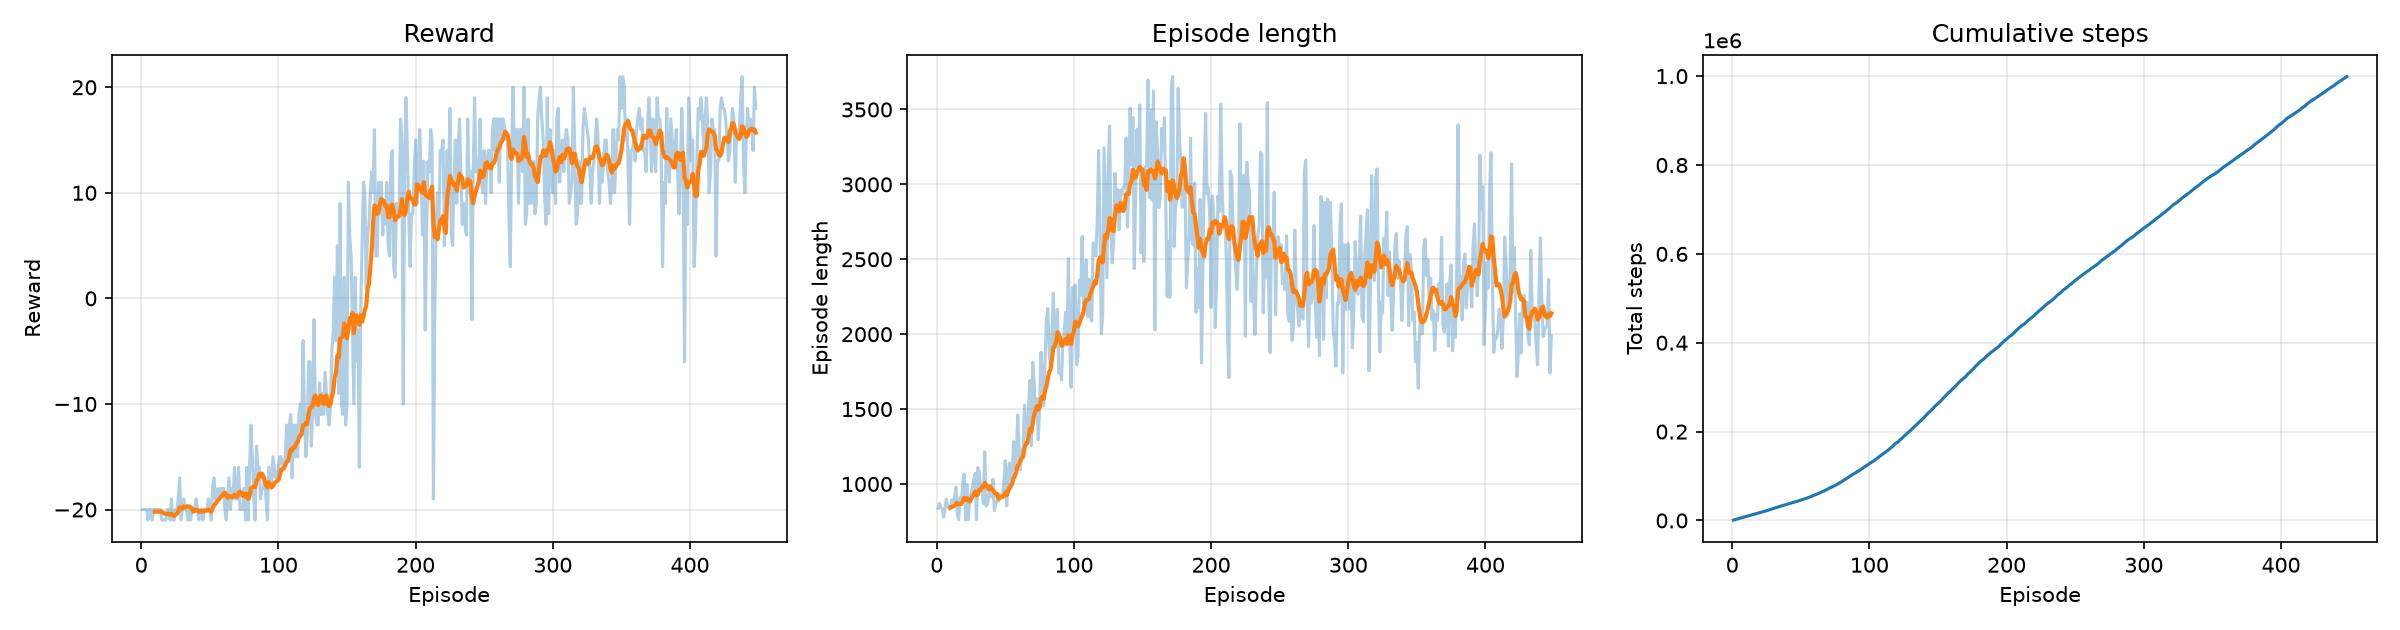

In [17]:
if len(records) != 10:
    print("Complete all ten experiments before final selection. Save the partial outputs below.")
else:
    best = choose_best(range(1, 11))
    best_folder = OUTPUT / f"experiment_{best['experiment']}"
    shutil.copy2(best_folder / "model.pth", OUTPUT / "dqn_model.pth")
    (OUTPUT / "selected_model.json").write_text(json.dumps(best, indent=2))
    plots = OUTPUT / "plots"
    # The kernel sets an inline matplotlib backend; scripts need a file-only backend.
    subprocess.run(["uv", "run", "plot_results.py", str(best_folder / "training.csv"), "--out_dir", str(plots)], check=True, env=dict(os.environ, MPLBACKEND="Agg"))
    final_path = OUTPUT / "independent_evaluation.json"
    if not final_path.exists():
        subprocess.run(["uv", "run", "python", str(EVALUATOR), str(OUTPUT / "dqn_model.pth"), str(final_path), "--episodes", "20", "--seed", "1000"], check=True)
    final = json.loads(final_path.read_text())
    final_text = f"\n## Selected model: experiment {best['experiment']}\n\nIndependent mean return: **{final['mean_reward']:+.2f}**; standard deviation {final['std_reward']:.2f}; wins **{final['wins']}/20**. Seeds 1000–1019.\n"
    (OUTPUT / "results.md").write_text(report + final_text)
    display(Markdown(final_text))
    display(Image(filename=str(plots / "training_summary.png")))
    video = OUTPUT / "gameplay.mp4"
    video_result = OUTPUT / "gameplay.json"
    if not video_result.exists():
        if video.exists(): raise RuntimeError("Partial video exists; preserve or remove it before recording again.")
        subprocess.run(["uv", "run", "python", str(EVALUATOR), str(OUTPUT / "dqn_model.pth"), str(video_result), "--episodes", "1", "--seed", "2000", "--video", str(video)], check=True)
    display(Video(str(video), embed=True))


## Samuel's explanation for the presentation
- **Shared interfaces:** Divine's preprocessing produces uint8 `(4,84,84)` observations. Her CNN maps `(B,4,84,84)` to `(B,6)` Q-values. Gabriel supplies replay samples and the training schedule.
- **Training update:** Samuel's `train_step` gathers the chosen-action Q-value and computes `r + gamma * (1 - terminated) * max(target(next_state))`. Huber loss and gradient clipping update only the online network. The target network is synchronized every 1,000 decisions.
- **Logging and saving:** episode CSV records return, length, cumulative decisions, epsilon and latest loss. Final inference weights and run provenance are retained. Partial final episodes are absent from the CSV; successful training process completion records the full budget.
- **Architecture:** four stacked grayscale frames → Conv(32, kernel 8, stride 4) → Conv(64, kernel 4, stride 2) → Conv(64, kernel 3, stride 1) → flatten 3136 → dense 512 → six Q-values. ReLU follows convolution and hidden dense layers. Normalize pixels once inside the CNN.
- **Key findings:** a lower starting epsilon helped most (exp 8, epsilon 0.5: last-100 +14.60; exp 9, 0.75: +12.92; baseline 1.0: +6.39). Changing batch size alone at the base learning rate did not beat the baseline's test score. Larger batches improved only with a higher learning rate (exp 6 +9.08 vs exp 4 +3.91; exp 7 +4.40 vs exp 5 +3.28). Combining the best batch size and epsilon (exp 10: batch 8 + epsilon 0.5) was the weakest run (−4.02), because batch 8's slow, noisy learning dominated.
- **Results discussion:** use the measured tables to describe best/worst runs, explain exploration versus exploitation and batch/update trade-offs, and distinguish training averages, selection scores and independent evaluation. Do not describe an unexecuted run as completed.

The selected model (experiment 8) is already exported as the project root `dqn_model.pth`; run `uv run play.py` for the live demonstration. The ZIP keeps every experiment's weights and evidence.


In [18]:
# Display the exact shared implementation used by this notebook for the presentation.
show_code = "import inspect, train; " + "; ".join(
    f"print('\\n### {name}\\n'); print(inspect.getsource(train.{name}))"
    for name in ["train_step", "sync_target", "Logger", "save_model"]
)
subprocess.run(["uv", "run", "python", "-c", show_code], check=True)



### train_step

def train_step(online_net, target_net, optimizer, batch, gamma):
    """Update vanilla DQN from Gabriel's sampled-batch interface.

    Replay now returns uint8 images; the CNN normalizes them internally.
    Terminations mask bootstrapping; time-limit truncations do not.
    """
    states, actions, rewards, next_states, dones = batch
    if states.shape[0] == 0:
        raise ValueError("Training requires a nonempty batch")
    online_net.train()
    target_net.eval()
    q = online_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)
    with torch.no_grad():
        next_q = target_net(next_states).max(dim=1).values
        target = rewards + gamma * next_q * (1.0 - dones)
    loss = F.smooth_l1_loss(q, target)
    if not torch.isfinite(loss):
        raise FloatingPointError("Non-finite DQN loss; optimizer update skipped")
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(online_net.parameters(), 10.0, error_if_nonf

CompletedProcess(args=['uv', 'run', 'python', '-c', "import inspect, train; print('\\n### train_step\\n'); print(inspect.getsource(train.train_step)); print('\\n### sync_target\\n'); print(inspect.getsource(train.sync_target)); print('\\n### Logger\\n'); print(inspect.getsource(train.Logger)); print('\\n### save_model\\n'); print(inspect.getsource(train.save_model))"], returncode=0)

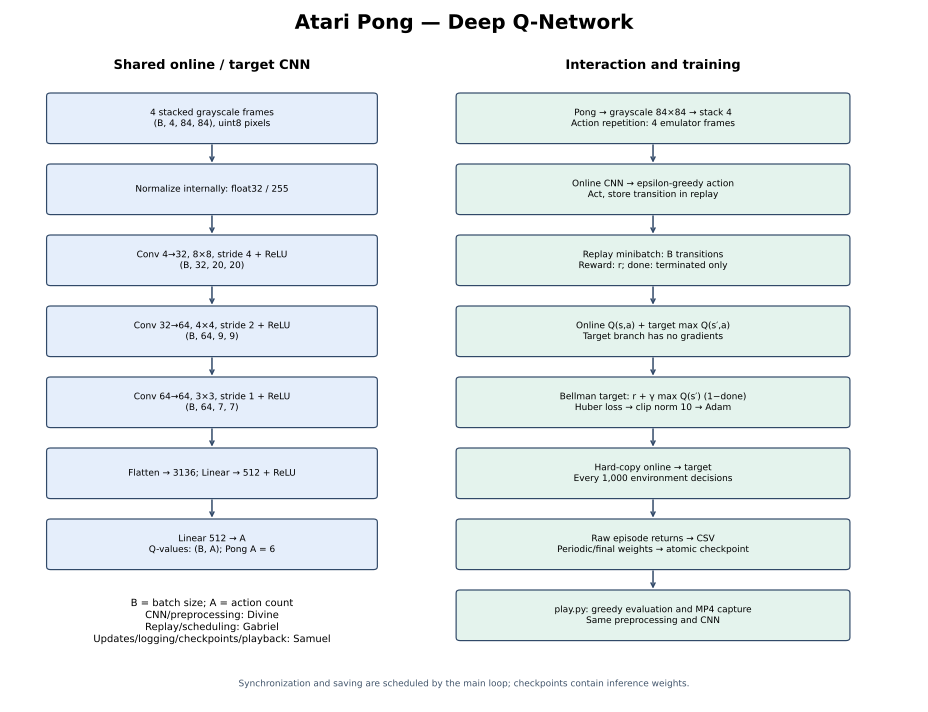

In [19]:
from IPython.display import SVG
display(SVG(data='<?xml version="1.0" encoding="utf-8" standalone="no"?>\n<!DOCTYPE svg PUBLIC "-//W3C//DTD SVG 1.1//EN"\n  "http://www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd">\n<svg xmlns:xlink="http://www.w3.org/1999/xlink" width="928.8pt" height="712.8pt" viewBox="0 0 928.8 712.8" xmlns="http://www.w3.org/2000/svg" version="1.1">\n <metadata>\n  <rdf:RDF xmlns:dc="http://purl.org/dc/elements/1.1/" xmlns:cc="http://creativecommons.org/ns#" xmlns:rdf="http://www.w3.org/1999/02/22-rdf-syntax-ns#">\n   <cc:Work>\n    <dc:type rdf:resource="http://purl.org/dc/dcmitype/StillImage"/>\n    <dc:date>2026-11-13T21:41:51.808371</dc:date>\n    <dc:format>image/svg+xml</dc:format>\n    <dc:creator>\n     <cc:Agent>\n      <dc:title>Matplotlib v3.11.2, https://matplotlib.org/</dc:title>\n     </cc:Agent>\n    </dc:creator>\n   </cc:Work>\n  </rdf:RDF>\n </metadata>\n <defs>\n  <style type="text/css">*{stroke-linejoin: round; stroke-linecap: butt}</style>\n </defs>\n <g id="figure_1">\n  <g id="patch_1">\n   <path d="M 0 712.8\nL 928.8 712.8\nL 928.8 0\nL 0 0\nz\n" style="fill: #ffffff"/>\n  </g>\n  <g id="axes_1">\n   <g id="patch_2">\n    <path d="M 50.555172 143.789735\nL 373.748276 143.789735\nQ 377.689655 143.789735 377.689655 140.699469\nL 377.689655 96.199646\nQ 377.689655 93.109381 373.748276 93.109381\nL 50.555172 93.109381\nQ 46.613793 93.109381 46.613793 96.199646\nL 46.613793 140.699469\nQ 46.613793 143.789735 50.555172 143.789735\nz\n" clip-path="url(#p8a00b87742)" style="fill: #e5eefb; stroke: #314968; stroke-width: 1.2; stroke-linejoin: miter"/>\n   </g>\n   <g id="patch_3">\n    <path d="M 50.555172 214.865841\nL 373.748276 214.865841\nQ 377.689655 214.865841 377.689655 211.775575\nL 377.689655 167.275752\nQ 377.689655 164.185487 373.748276 164.185487\nL 50.555172 164.185487\nQ 46.613793 164.185487 46.613793 167.275752\nL 46.613793 211.775575\nQ 46.613793 214.865841 50.555172 214.865841\nz\n" clip-path="url(#p8a00b87742)" style="fill: #e5eefb; stroke: #314968; stroke-width: 1.2; stroke-linejoin: miter"/>\n   </g>\n   <g id="patch_4">\n    <path d="M 50.555172 285.941947\nL 373.748276 285.941947\nQ 377.689655 285.941947 377.689655 282.851681\nL 377.689655 238.351858\nQ 377.689655 235.261593 373.748276 235.261593\nL 50.555172 235.261593\nQ 46.613793 235.261593 46.613793 238.351858\nL 46.613793 282.851681\nQ 46.613793 285.941947 50.555172 285.941947\nz\n" clip-path="url(#p8a00b87742)" style="fill: #e5eefb; stroke: #314968; stroke-width: 1.2; stroke-linejoin: miter"/>\n   </g>\n   <g id="patch_5">\n    <path d="M 50.555172 357.018053\nL 373.748276 357.018053\nQ 377.689655 357.018053 377.689655 353.927788\nL 377.689655 309.427965\nQ 377.689655 306.337699 373.748276 306.337699\nL 50.555172 306.337699\nQ 46.613793 306.337699 46.613793 309.427965\nL 46.613793 353.927788\nQ 46.613793 357.018053 50.555172 357.018053\nz\n" clip-path="url(#p8a00b87742)" style="fill: #e5eefb; stroke: #314968; stroke-width: 1.2; stroke-linejoin: miter"/>\n   </g>\n   <g id="patch_6">\n    <path d="M 50.555172 428.094159\nL 373.748276 428.094159\nQ 377.689655 428.094159 377.689655 425.003894\nL 377.689655 380.504071\nQ 377.689655 377.413805 373.748276 377.413805\nL 50.555172 377.413805\nQ 46.613793 377.413805 46.613793 380.504071\nL 46.613793 425.003894\nQ 46.613793 428.094159 50.555172 428.094159\nz\n" clip-path="url(#p8a00b87742)" style="fill: #e5eefb; stroke: #314968; stroke-width: 1.2; stroke-linejoin: miter"/>\n   </g>\n   <g id="patch_7">\n    <path d="M 50.555172 499.170265\nL 373.748276 499.170265\nQ 377.689655 499.170265 377.689655 496.08\nL 377.689655 451.580177\nQ 377.689655 448.489912 373.748276 448.489912\nL 50.555172 448.489912\nQ 46.613793 448.489912 46.613793 451.580177\nL 46.613793 496.08\nQ 46.613793 499.170265 50.555172 499.170265\nz\n" clip-path="url(#p8a00b87742)" style="fill: #e5eefb; stroke: #314968; stroke-width: 1.2; stroke-linejoin: miter"/>\n   </g>\n   <g id="patch_8">\n    <path d="M 50.555172 570.246372\nL 373.748276 570.246372\nQ 377.689655 570.246372 377.689655 567.156106\nL 377.689655 522.656283\nQ 377.689655 519.566018 373.748276 519.566018\nL 50.555172 519.566018\nQ 46.613793 519.566018 46.613793 522.656283\nL 46.613793 567.156106\nQ 46.613793 570.246372 50.555172 570.246372\nz\n" clip-path="url(#p8a00b87742)" style="fill: #e5eefb; stroke: #314968; stroke-width: 1.2; stroke-linejoin: miter"/>\n   </g>\n   <g id="patch_9">\n    <path d="M 460.458621 143.789735\nL 846.713793 143.789735\nQ 850.655172 143.789735 850.655172 140.699469\nL 850.655172 96.199646\nQ 850.655172 93.109381 846.713793 93.109381\nL 460.458621 93.109381\nQ 456.517241 93.109381 456.517241 96.199646\nL 456.517241 140.699469\nQ 456.517241 143.789735 460.458621 143.789735\nz\n" clip-path="url(#p8a00b87742)" style="fill: #e4f3ed; stroke: #314968; stroke-width: 1.2; stroke-linejoin: miter"/>\n   </g>\n   <g id="patch_10">\n    <path d="M 460.458621 214.865841\nL 846.713793 214.865841\nQ 850.655172 214.865841 850.655172 211.775575\nL 850.655172 167.275752\nQ 850.655172 164.185487 846.713793 164.185487\nL 460.458621 164.185487\nQ 456.517241 164.185487 456.517241 167.275752\nL 456.517241 211.775575\nQ 456.517241 214.865841 460.458621 214.865841\nz\n" clip-path="url(#p8a00b87742)" style="fill: #e4f3ed; stroke: #314968; stroke-width: 1.2; stroke-linejoin: miter"/>\n   </g>\n   <g id="patch_11">\n    <path d="M 460.458621 285.941947\nL 846.713793 285.941947\nQ 850.655172 285.941947 850.655172 282.851681\nL 850.655172 238.351858\nQ 850.655172 235.261593 846.713793 235.261593\nL 460.458621 235.261593\nQ 456.517241 235.261593 456.517241 238.351858\nL 456.517241 282.851681\nQ 456.517241 285.941947 460.458621 285.941947\nz\n" clip-path="url(#p8a00b87742)" style="fill: #e4f3ed; stroke: #314968; stroke-width: 1.2; stroke-linejoin: miter"/>\n   </g>\n   <g id="patch_12">\n    <path d="M 460.458621 357.018053\nL 846.713793 357.018053\nQ 850.655172 357.018053 850.655172 353.927788\nL 850.655172 309.427965\nQ 850.655172 306.337699 846.713793 306.337699\nL 460.458621 306.337699\nQ 456.517241 306.337699 456.517241 309.427965\nL 456.517241 353.927788\nQ 456.517241 357.018053 460.458621 357.018053\nz\n" clip-path="url(#p8a00b87742)" style="fill: #e4f3ed; stroke: #314968; stroke-width: 1.2; stroke-linejoin: miter"/>\n   </g>\n   <g id="patch_13">\n    <path d="M 460.458621 428.094159\nL 846.713793 428.094159\nQ 850.655172 428.094159 850.655172 425.003894\nL 850.655172 380.504071\nQ 850.655172 377.413805 846.713793 377.413805\nL 460.458621 377.413805\nQ 456.517241 377.413805 456.517241 380.504071\nL 456.517241 425.003894\nQ 456.517241 428.094159 460.458621 428.094159\nz\n" clip-path="url(#p8a00b87742)" style="fill: #e4f3ed; stroke: #314968; stroke-width: 1.2; stroke-linejoin: miter"/>\n   </g>\n   <g id="patch_14">\n    <path d="M 460.458621 499.170265\nL 846.713793 499.170265\nQ 850.655172 499.170265 850.655172 496.08\nL 850.655172 451.580177\nQ 850.655172 448.489912 846.713793 448.489912\nL 460.458621 448.489912\nQ 456.517241 448.489912 456.517241 451.580177\nL 456.517241 496.08\nQ 456.517241 499.170265 460.458621 499.170265\nz\n" clip-path="url(#p8a00b87742)" style="fill: #e4f3ed; stroke: #314968; stroke-width: 1.2; stroke-linejoin: miter"/>\n   </g>\n   <g id="patch_15">\n    <path d="M 460.458621 570.246372\nL 846.713793 570.246372\nQ 850.655172 570.246372 850.655172 567.156106\nL 850.655172 522.656283\nQ 850.655172 519.566018 846.713793 519.566018\nL 460.458621 519.566018\nQ 456.517241 519.566018 456.517241 522.656283\nL 456.517241 567.156106\nQ 456.517241 570.246372 460.458621 570.246372\nz\n" clip-path="url(#p8a00b87742)" style="fill: #e4f3ed; stroke: #314968; stroke-width: 1.2; stroke-linejoin: miter"/>\n   </g>\n   <g id="patch_16">\n    <path d="M 460.458621 641.322478\nL 846.713793 641.322478\nQ 850.655172 641.322478 850.655172 638.232212\nL 850.655172 593.732389\nQ 850.655172 590.642124 846.713793 590.642124\nL 460.458621 590.642124\nQ 456.517241 590.642124 456.517241 593.732389\nL 456.517241 638.232212\nQ 456.517241 641.322478 460.458621 641.322478\nz\n" clip-path="url(#p8a00b87742)" style="fill: #e4f3ed; stroke: #314968; stroke-width: 1.2; stroke-linejoin: miter"/>\n   </g>\n   <g id="text_1">\n    <!-- Atari Pong — Deep Q-Network -->\n    <g transform="translate(294.8875 28.831858) scale(0.2 -0.2)">\n     <defs>\n      <path id="DejaVuSans-Bold-24" d="M 3419 850\nL 1538 850\nL 1241 0\nL 31 0\nL 1759 4666\nL 3194 4666\nL 4922 0\nL 3713 0\nL 3419 850\nz\nM 1838 1716\nL 3116 1716\nL 2478 3572\nL 1838 1716\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-57" d="M 1759 4494\nL 1759 3500\nL 2913 3500\nL 2913 2700\nL 1759 2700\nL 1759 1216\nQ 1759 972 1856 886\nQ 1953 800 2241 800\nL 2816 800\nL 2816 0\nL 1856 0\nQ 1194 0 917 276\nQ 641 553 641 1216\nL 641 2700\nL 84 2700\nL 84 3500\nL 641 3500\nL 641 4494\nL 1759 4494\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-44" d="M 2106 1575\nQ 1756 1575 1579 1456\nQ 1403 1338 1403 1106\nQ 1403 894 1545 773\nQ 1688 653 1941 653\nQ 2256 653 2472 879\nQ 2688 1106 2688 1447\nL 2688 1575\nL 2106 1575\nz\nM 3816 1997\nL 3816 0\nL 2688 0\nL 2688 519\nQ 2463 200 2181 54\nQ 1900 -91 1497 -91\nQ 953 -91 614 226\nQ 275 544 275 1050\nQ 275 1666 698 1953\nQ 1122 2241 2028 2241\nL 2688 2241\nL 2688 2328\nQ 2688 2594 2478 2717\nQ 2269 2841 1825 2841\nQ 1466 2841 1156 2769\nQ 847 2697 581 2553\nL 581 3406\nQ 941 3494 1303 3539\nQ 1666 3584 2028 3584\nQ 2975 3584 3395 3211\nQ 3816 2838 3816 1997\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-55" d="M 3138 2547\nQ 2991 2616 2845 2648\nQ 2700 2681 2553 2681\nQ 2122 2681 1889 2404\nQ 1656 2128 1656 1613\nL 1656 0\nL 538 0\nL 538 3500\nL 1656 3500\nL 1656 2925\nQ 1872 3269 2151 3426\nQ 2431 3584 2822 3584\nQ 2878 3584 2943 3579\nQ 3009 3575 3134 3559\nL 3138 2547\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-4c" d="M 538 3500\nL 1656 3500\nL 1656 0\nL 538 0\nL 538 3500\nz\nM 538 4863\nL 1656 4863\nL 1656 3950\nL 538 3950\nL 538 4863\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-3" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-33" d="M 588 4666\nL 2584 4666\nQ 3475 4666 3951 4270\nQ 4428 3875 4428 3144\nQ 4428 2409 3951 2014\nQ 3475 1619 2584 1619\nL 1791 1619\nL 1791 0\nL 588 0\nL 588 4666\nz\nM 1791 3794\nL 1791 2491\nL 2456 2491\nQ 2806 2491 2997 2661\nQ 3188 2831 3188 3144\nQ 3188 3456 2997 3625\nQ 2806 3794 2456 3794\nL 1791 3794\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-52" d="M 2203 2784\nQ 1831 2784 1636 2517\nQ 1441 2250 1441 1747\nQ 1441 1244 1636 976\nQ 1831 709 2203 709\nQ 2569 709 2762 976\nQ 2956 1244 2956 1747\nQ 2956 2250 2762 2517\nQ 2569 2784 2203 2784\nz\nM 2203 3584\nQ 3106 3584 3614 3096\nQ 4122 2609 4122 1747\nQ 4122 884 3614 396\nQ 3106 -91 2203 -91\nQ 1297 -91 786 396\nQ 275 884 275 1747\nQ 275 2609 786 3096\nQ 1297 3584 2203 3584\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-51" d="M 4056 2131\nL 4056 0\nL 2931 0\nL 2931 347\nL 2931 1631\nQ 2931 2084 2911 2256\nQ 2891 2428 2841 2509\nQ 2775 2619 2662 2680\nQ 2550 2741 2406 2741\nQ 2056 2741 1856 2470\nQ 1656 2200 1656 1722\nL 1656 0\nL 538 0\nL 538 3500\nL 1656 3500\nL 1656 2988\nQ 1909 3294 2193 3439\nQ 2478 3584 2822 3584\nQ 3428 3584 3742 3212\nQ 4056 2841 4056 2131\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-4a" d="M 2919 594\nQ 2688 288 2409 144\nQ 2131 0 1766 0\nQ 1125 0 706 504\nQ 288 1009 288 1791\nQ 288 2575 706 3076\nQ 1125 3578 1766 3578\nQ 2131 3578 2409 3434\nQ 2688 3291 2919 2981\nL 2919 3500\nL 4044 3500\nL 4044 353\nQ 4044 -491 3511 -936\nQ 2978 -1381 1966 -1381\nQ 1638 -1381 1331 -1331\nQ 1025 -1281 716 -1178\nL 716 -306\nQ 1009 -475 1290 -558\nQ 1572 -641 1856 -641\nQ 2406 -641 2662 -400\nQ 2919 -159 2919 353\nL 2919 594\nz\nM 2181 2772\nQ 1834 2772 1640 2515\nQ 1447 2259 1447 1791\nQ 1447 1309 1634 1061\nQ 1822 813 2181 813\nQ 2531 813 2725 1069\nQ 2919 1325 2919 1791\nQ 2919 2259 2725 2515\nQ 2531 2772 2181 2772\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-af6" d="M 344 2156\nL 6056 2156\nL 6056 1350\nL 344 1350\nL 344 2156\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-27" d="M 1791 3756\nL 1791 909\nL 2222 909\nQ 2959 909 3348 1275\nQ 3738 1641 3738 2338\nQ 3738 3031 3350 3393\nQ 2963 3756 2222 3756\nL 1791 3756\nz\nM 588 4666\nL 1856 4666\nQ 2919 4666 3439 4514\nQ 3959 4363 4331 4000\nQ 4659 3684 4818 3271\nQ 4978 2859 4978 2338\nQ 4978 1809 4818 1395\nQ 4659 981 4331 666\nQ 3956 303 3431 151\nQ 2906 0 1856 0\nL 588 0\nL 588 4666\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-48" d="M 4031 1759\nL 4031 1441\nL 1416 1441\nQ 1456 1047 1700 850\nQ 1944 653 2381 653\nQ 2734 653 3104 758\nQ 3475 863 3866 1075\nL 3866 213\nQ 3469 63 3072 -14\nQ 2675 -91 2278 -91\nQ 1328 -91 801 392\nQ 275 875 275 1747\nQ 275 2603 792 3093\nQ 1309 3584 2216 3584\nQ 3041 3584 3536 3087\nQ 4031 2591 4031 1759\nz\nM 2881 2131\nQ 2881 2450 2695 2645\nQ 2509 2841 2209 2841\nQ 1884 2841 1681 2658\nQ 1478 2475 1428 2131\nL 2881 2131\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-53" d="M 1656 506\nL 1656 -1331\nL 538 -1331\nL 538 3500\nL 1656 3500\nL 1656 2988\nQ 1888 3294 2169 3439\nQ 2450 3584 2816 3584\nQ 3463 3584 3878 3070\nQ 4294 2556 4294 1747\nQ 4294 938 3878 423\nQ 3463 -91 2816 -91\nQ 2450 -91 2169 54\nQ 1888 200 1656 506\nz\nM 2400 2772\nQ 2041 2772 1848 2508\nQ 1656 2244 1656 1747\nQ 1656 1250 1848 986\nQ 2041 722 2400 722\nQ 2759 722 2948 984\nQ 3138 1247 3138 1747\nQ 3138 2247 2948 2509\nQ 2759 2772 2400 2772\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-34" d="M 2847 -84\nL 2753 -84\nQ 1600 -84 959 553\nQ 319 1191 319 2328\nQ 319 3463 958 4106\nQ 1597 4750 2719 4750\nQ 3853 4750 4486 4112\nQ 5119 3475 5119 2328\nQ 5119 1541 4783 972\nQ 4447 403 3816 116\nL 4756 -934\nL 3609 -934\nL 2847 -84\nz\nM 2719 3878\nQ 2169 3878 1866 3472\nQ 1563 3066 1563 2328\nQ 1563 1578 1859 1179\nQ 2156 781 2719 781\nQ 3272 781 3575 1187\nQ 3878 1594 3878 2328\nQ 3878 3066 3575 3472\nQ 3272 3878 2719 3878\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-10" d="M 347 2297\nL 2309 2297\nL 2309 1388\nL 347 1388\nL 347 2297\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-31" d="M 588 4666\nL 1931 4666\nL 3628 1466\nL 3628 4666\nL 4769 4666\nL 4769 0\nL 3425 0\nL 1728 3200\nL 1728 0\nL 588 0\nL 588 4666\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-5a" d="M 225 3500\nL 1313 3500\nL 1900 1088\nL 2491 3500\nL 3425 3500\nL 4013 1113\nL 4603 3500\nL 5691 3500\nL 4769 0\nL 3547 0\nL 2956 2406\nL 2369 0\nL 1147 0\nL 225 3500\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-4e" d="M 538 4863\nL 1656 4863\nL 1656 2216\nL 2944 3500\nL 4244 3500\nL 2534 1894\nL 4378 0\nL 3022 0\nL 1656 1459\nL 1656 0\nL 538 0\nL 538 4863\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-Bold-24"/>\n     <use xlink:href="#DejaVuSans-Bold-57" transform="translate(77.390625 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-44" transform="translate(125.1875 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-55" transform="translate(192.671875 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-4c" transform="translate(241.984375 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-3" transform="translate(276.265625 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-33" transform="translate(311.078125 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-52" transform="translate(384.375 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-51" transform="translate(453.078125 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-4a" transform="translate(524.265625 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-3" transform="translate(595.84375 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-af6" transform="translate(630.65625 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-3" transform="translate(730.65625 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-27" transform="translate(765.46875 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-48" transform="translate(848.484375 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-48" transform="translate(916.3125 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-53" transform="translate(984.140625 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-3" transform="translate(1055.71875 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-34" transform="translate(1090.53125 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-10" transform="translate(1177.40625 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-31" transform="translate(1218.90625 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-48" transform="translate(1302.59375 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-57" transform="translate(1370.421875 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-5a" transform="translate(1418.21875 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-52" transform="translate(1510.609375 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-55" transform="translate(1579.3125 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-4e" transform="translate(1628.625 0)"/>\n    </g>\n   </g>\n   <g id="text_2">\n    <!-- Shared online / target CNN -->\n    <g transform="translate(113.662505 69.00531) scale(0.13 -0.13)">\n     <defs>\n      <path id="DejaVuSans-Bold-36" d="M 3834 4519\nL 3834 3531\nQ 3450 3703 3084 3790\nQ 2719 3878 2394 3878\nQ 1963 3878 1756 3759\nQ 1550 3641 1550 3391\nQ 1550 3203 1689 3098\nQ 1828 2994 2194 2919\nL 2706 2816\nQ 3484 2659 3812 2340\nQ 4141 2022 4141 1434\nQ 4141 663 3683 286\nQ 3225 -91 2284 -91\nQ 1841 -91 1394 -6\nQ 947 78 500 244\nL 500 1259\nQ 947 1022 1364 901\nQ 1781 781 2169 781\nQ 2563 781 2772 912\nQ 2981 1044 2981 1288\nQ 2981 1506 2839 1625\nQ 2697 1744 2272 1838\nL 1806 1941\nQ 1106 2091 782 2419\nQ 459 2747 459 3303\nQ 459 4000 909 4375\nQ 1359 4750 2203 4750\nQ 2588 4750 2994 4692\nQ 3400 4634 3834 4519\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-4b" d="M 4056 2131\nL 4056 0\nL 2931 0\nL 2931 347\nL 2931 1625\nQ 2931 2084 2911 2256\nQ 2891 2428 2841 2509\nQ 2775 2619 2662 2680\nQ 2550 2741 2406 2741\nQ 2056 2741 1856 2470\nQ 1656 2200 1656 1722\nL 1656 0\nL 538 0\nL 538 4863\nL 1656 4863\nL 1656 2988\nQ 1909 3294 2193 3439\nQ 2478 3584 2822 3584\nQ 3428 3584 3742 3212\nQ 4056 2841 4056 2131\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-47" d="M 2919 2988\nL 2919 4863\nL 4044 4863\nL 4044 0\nL 2919 0\nL 2919 506\nQ 2688 197 2409 53\nQ 2131 -91 1766 -91\nQ 1119 -91 703 423\nQ 288 938 288 1747\nQ 288 2556 703 3070\nQ 1119 3584 1766 3584\nQ 2128 3584 2408 3439\nQ 2688 3294 2919 2988\nz\nM 2181 722\nQ 2541 722 2730 984\nQ 2919 1247 2919 1747\nQ 2919 2247 2730 2509\nQ 2541 2772 2181 2772\nQ 1825 2772 1636 2509\nQ 1447 2247 1447 1747\nQ 1447 1247 1636 984\nQ 1825 722 2181 722\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-4f" d="M 538 4863\nL 1656 4863\nL 1656 0\nL 538 0\nL 538 4863\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-12" d="M 1644 4666\nL 2338 4666\nL 691 -594\nL 0 -594\nL 1644 4666\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-26" d="M 4288 256\nQ 3956 84 3597 -3\nQ 3238 -91 2847 -91\nQ 1681 -91 1000 561\nQ 319 1213 319 2328\nQ 319 3447 1000 4098\nQ 1681 4750 2847 4750\nQ 3238 4750 3597 4662\nQ 3956 4575 4288 4403\nL 4288 3438\nQ 3953 3666 3628 3772\nQ 3303 3878 2944 3878\nQ 2300 3878 1931 3465\nQ 1563 3053 1563 2328\nQ 1563 1606 1931 1193\nQ 2300 781 2944 781\nQ 3303 781 3628 887\nQ 3953 994 4288 1222\nL 4288 256\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-Bold-36"/>\n     <use xlink:href="#DejaVuSans-Bold-4b" transform="translate(72.015625 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-44" transform="translate(143.203125 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-55" transform="translate(210.6875 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-48" transform="translate(260 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-47" transform="translate(327.828125 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-3" transform="translate(399.40625 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-52" transform="translate(434.21875 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-51" transform="translate(502.921875 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-4f" transform="translate(574.109375 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-4c" transform="translate(608.390625 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-51" transform="translate(642.671875 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-48" transform="translate(713.859375 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-3" transform="translate(781.6875 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-12" transform="translate(816.5 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-3" transform="translate(853.03125 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-57" transform="translate(887.84375 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-44" transform="translate(935.640625 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-55" transform="translate(1003.125 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-4a" transform="translate(1052.4375 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-48" transform="translate(1124.015625 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-57" transform="translate(1191.84375 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-3" transform="translate(1239.640625 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-26" transform="translate(1274.453125 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-31" transform="translate(1347.84375 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-31" transform="translate(1431.53125 0)"/>\n    </g>\n   </g>\n   <g id="text_3">\n    <!-- 4 stacked grayscale frames -->\n    <g transform="translate(150.175474 115.386569) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-17" d="M 2419 4116\nL 825 1625\nL 2419 1625\nL 2419 4116\nz\nM 2253 4666\nL 3047 4666\nL 3047 1625\nL 3713 1625\nL 3713 1100\nL 3047 1100\nL 3047 0\nL 2419 0\nL 2419 1100\nL 313 1100\nL 313 1709\nL 2253 4666\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-3" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-56" d="M 2834 3397\nL 2834 2853\nQ 2591 2978 2328 3040\nQ 2066 3103 1784 3103\nQ 1356 3103 1142 2972\nQ 928 2841 928 2578\nQ 928 2378 1081 2264\nQ 1234 2150 1697 2047\nL 1894 2003\nQ 2506 1872 2764 1633\nQ 3022 1394 3022 966\nQ 3022 478 2636 193\nQ 2250 -91 1575 -91\nQ 1294 -91 989 -36\nQ 684 19 347 128\nL 347 722\nQ 666 556 975 473\nQ 1284 391 1588 391\nQ 1994 391 2212 530\nQ 2431 669 2431 922\nQ 2431 1156 2273 1281\nQ 2116 1406 1581 1522\nL 1381 1569\nQ 847 1681 609 1914\nQ 372 2147 372 2553\nQ 372 3047 722 3315\nQ 1072 3584 1716 3584\nQ 2034 3584 2315 3537\nQ 2597 3491 2834 3397\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-57" d="M 1172 4494\nL 1172 3500\nL 2356 3500\nL 2356 3053\nL 1172 3053\nL 1172 1153\nQ 1172 725 1289 603\nQ 1406 481 1766 481\nL 2356 481\nL 2356 0\nL 1766 0\nQ 1100 0 847 248\nQ 594 497 594 1153\nL 594 3053\nL 172 3053\nL 172 3500\nL 594 3500\nL 594 4494\nL 1172 4494\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-44" d="M 2194 1759\nQ 1497 1759 1228 1600\nQ 959 1441 959 1056\nQ 959 750 1161 570\nQ 1363 391 1709 391\nQ 2188 391 2477 730\nQ 2766 1069 2766 1631\nL 2766 1759\nL 2194 1759\nz\nM 3341 1997\nL 3341 0\nL 2766 0\nL 2766 531\nQ 2569 213 2275 61\nQ 1981 -91 1556 -91\nQ 1019 -91 701 211\nQ 384 513 384 1019\nQ 384 1609 779 1909\nQ 1175 2209 1959 2209\nL 2766 2209\nL 2766 2266\nQ 2766 2663 2505 2880\nQ 2244 3097 1772 3097\nQ 1472 3097 1187 3025\nQ 903 2953 641 2809\nL 641 3341\nQ 956 3463 1253 3523\nQ 1550 3584 1831 3584\nQ 2591 3584 2966 3190\nQ 3341 2797 3341 1997\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-46" d="M 3122 3366\nL 3122 2828\nQ 2878 2963 2633 3030\nQ 2388 3097 2138 3097\nQ 1578 3097 1268 2742\nQ 959 2388 959 1747\nQ 959 1106 1268 751\nQ 1578 397 2138 397\nQ 2388 397 2633 464\nQ 2878 531 3122 666\nL 3122 134\nQ 2881 22 2623 -34\nQ 2366 -91 2075 -91\nQ 1284 -91 818 406\nQ 353 903 353 1747\nQ 353 2603 823 3093\nQ 1294 3584 2113 3584\nQ 2378 3584 2631 3529\nQ 2884 3475 3122 3366\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-4e" d="M 581 4863\nL 1159 4863\nL 1159 1991\nL 2875 3500\nL 3609 3500\nL 1753 1863\nL 3688 0\nL 2938 0\nL 1159 1709\nL 1159 0\nL 581 0\nL 581 4863\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-48" d="M 3597 1894\nL 3597 1613\nL 953 1613\nQ 991 1019 1311 708\nQ 1631 397 2203 397\nQ 2534 397 2845 478\nQ 3156 559 3463 722\nL 3463 178\nQ 3153 47 2828 -22\nQ 2503 -91 2169 -91\nQ 1331 -91 842 396\nQ 353 884 353 1716\nQ 353 2575 817 3079\nQ 1281 3584 2069 3584\nQ 2775 3584 3186 3129\nQ 3597 2675 3597 1894\nz\nM 3022 2063\nQ 3016 2534 2758 2815\nQ 2500 3097 2075 3097\nQ 1594 3097 1305 2825\nQ 1016 2553 972 2059\nL 3022 2063\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-47" d="M 2906 2969\nL 2906 4863\nL 3481 4863\nL 3481 0\nL 2906 0\nL 2906 525\nQ 2725 213 2448 61\nQ 2172 -91 1784 -91\nQ 1150 -91 751 415\nQ 353 922 353 1747\nQ 353 2572 751 3078\nQ 1150 3584 1784 3584\nQ 2172 3584 2448 3432\nQ 2725 3281 2906 2969\nz\nM 947 1747\nQ 947 1113 1208 752\nQ 1469 391 1925 391\nQ 2381 391 2643 752\nQ 2906 1113 2906 1747\nQ 2906 2381 2643 2742\nQ 2381 3103 1925 3103\nQ 1469 3103 1208 2742\nQ 947 2381 947 1747\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-4a" d="M 2906 1791\nQ 2906 2416 2648 2759\nQ 2391 3103 1925 3103\nQ 1463 3103 1205 2759\nQ 947 2416 947 1791\nQ 947 1169 1205 825\nQ 1463 481 1925 481\nQ 2391 481 2648 825\nQ 2906 1169 2906 1791\nz\nM 3481 434\nQ 3481 -459 3084 -895\nQ 2688 -1331 1869 -1331\nQ 1566 -1331 1297 -1286\nQ 1028 -1241 775 -1147\nL 775 -588\nQ 1028 -725 1275 -790\nQ 1522 -856 1778 -856\nQ 2344 -856 2625 -561\nQ 2906 -266 2906 331\nL 2906 616\nQ 2728 306 2450 153\nQ 2172 0 1784 0\nQ 1141 0 747 490\nQ 353 981 353 1791\nQ 353 2603 747 3093\nQ 1141 3584 1784 3584\nQ 2172 3584 2450 3431\nQ 2728 3278 2906 2969\nL 2906 3500\nL 3481 3500\nL 3481 434\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-55" d="M 2631 2963\nQ 2534 3019 2420 3045\nQ 2306 3072 2169 3072\nQ 1681 3072 1420 2755\nQ 1159 2438 1159 1844\nL 1159 0\nL 581 0\nL 581 3500\nL 1159 3500\nL 1159 2956\nQ 1341 3275 1631 3429\nQ 1922 3584 2338 3584\nQ 2397 3584 2469 3576\nQ 2541 3569 2628 3553\nL 2631 2963\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-5c" d="M 2059 -325\nQ 1816 -950 1584 -1140\nQ 1353 -1331 966 -1331\nL 506 -1331\nL 506 -850\nL 844 -850\nQ 1081 -850 1212 -737\nQ 1344 -625 1503 -206\nL 1606 56\nL 191 3500\nL 800 3500\nL 1894 763\nL 2988 3500\nL 3597 3500\nL 2059 -325\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-4f" d="M 603 4863\nL 1178 4863\nL 1178 0\nL 603 0\nL 603 4863\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-49" d="M 2375 4863\nL 2375 4384\nL 1825 4384\nQ 1516 4384 1395 4259\nQ 1275 4134 1275 3809\nL 1275 3500\nL 2222 3500\nL 2222 3053\nL 1275 3053\nL 1275 0\nL 697 0\nL 697 3053\nL 147 3053\nL 147 3500\nL 697 3500\nL 697 3744\nQ 697 4328 969 4595\nQ 1241 4863 1831 4863\nL 2375 4863\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-50" d="M 3328 2828\nQ 3544 3216 3844 3400\nQ 4144 3584 4550 3584\nQ 5097 3584 5394 3201\nQ 5691 2819 5691 2113\nL 5691 0\nL 5113 0\nL 5113 2094\nQ 5113 2597 4934 2840\nQ 4756 3084 4391 3084\nQ 3944 3084 3684 2787\nQ 3425 2491 3425 1978\nL 3425 0\nL 2847 0\nL 2847 2094\nQ 2847 2600 2669 2842\nQ 2491 3084 2119 3084\nQ 1678 3084 1418 2786\nQ 1159 2488 1159 1978\nL 1159 0\nL 581 0\nL 581 3500\nL 1159 3500\nL 1159 2956\nQ 1356 3278 1631 3431\nQ 1906 3584 2284 3584\nQ 2666 3584 2933 3390\nQ 3200 3197 3328 2828\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-17"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(63.625 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(95.40625 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(147.5 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(186.703125 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(247.984375 0)"/>\n     <use xlink:href="#DejaVuSans-4e" transform="translate(302.96875 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(357.3125 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(418.84375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(482.328125 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(514.109375 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(577.59375 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(618.703125 0)"/>\n     <use xlink:href="#DejaVuSans-5c" transform="translate(679.984375 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(739.171875 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(791.265625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(846.25 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(907.53125 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(935.3125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(996.84375 0)"/>\n     <use xlink:href="#DejaVuSans-49" transform="translate(1028.625 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(1063.828125 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1104.9375 0)"/>\n     <use xlink:href="#DejaVuSans-50" transform="translate(1166.21875 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1263.625 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(1325.15625 0)"/>\n    </g>\n    <!-- (B, 4, 84, 84), uint8 pixels -->\n    <g transform="translate(153.789537 126.18903) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-b" d="M 1984 4856\nQ 1566 4138 1362 3434\nQ 1159 2731 1159 2009\nQ 1159 1288 1364 580\nQ 1569 -128 1984 -844\nL 1484 -844\nQ 1016 -109 783 600\nQ 550 1309 550 2009\nQ 550 2706 781 3412\nQ 1013 4119 1484 4856\nL 1984 4856\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-25" d="M 1259 2228\nL 1259 519\nL 2272 519\nQ 2781 519 3026 730\nQ 3272 941 3272 1375\nQ 3272 1813 3026 2020\nQ 2781 2228 2272 2228\nL 1259 2228\nz\nM 1259 4147\nL 1259 2741\nL 2194 2741\nQ 2656 2741 2882 2914\nQ 3109 3088 3109 3444\nQ 3109 3797 2882 3972\nQ 2656 4147 2194 4147\nL 1259 4147\nz\nM 628 4666\nL 2241 4666\nQ 2963 4666 3353 4366\nQ 3744 4066 3744 3513\nQ 3744 3084 3544 2831\nQ 3344 2578 2956 2516\nQ 3422 2416 3680 2098\nQ 3938 1781 3938 1306\nQ 3938 681 3513 340\nQ 3088 0 2303 0\nL 628 0\nL 628 4666\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-f" d="M 750 794\nL 1409 794\nL 1409 256\nL 897 -744\nL 494 -744\nL 750 256\nL 750 794\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-1b" d="M 2034 2216\nQ 1584 2216 1326 1975\nQ 1069 1734 1069 1313\nQ 1069 891 1326 650\nQ 1584 409 2034 409\nQ 2484 409 2743 651\nQ 3003 894 3003 1313\nQ 3003 1734 2745 1975\nQ 2488 2216 2034 2216\nz\nM 1403 2484\nQ 997 2584 770 2862\nQ 544 3141 544 3541\nQ 544 4100 942 4425\nQ 1341 4750 2034 4750\nQ 2731 4750 3128 4425\nQ 3525 4100 3525 3541\nQ 3525 3141 3298 2862\nQ 3072 2584 2669 2484\nQ 3125 2378 3379 2068\nQ 3634 1759 3634 1313\nQ 3634 634 3220 271\nQ 2806 -91 2034 -91\nQ 1263 -91 848 271\nQ 434 634 434 1313\nQ 434 1759 690 2068\nQ 947 2378 1403 2484\nz\nM 1172 3481\nQ 1172 3119 1398 2916\nQ 1625 2713 2034 2713\nQ 2441 2713 2670 2916\nQ 2900 3119 2900 3481\nQ 2900 3844 2670 4047\nQ 2441 4250 2034 4250\nQ 1625 4250 1398 4047\nQ 1172 3844 1172 3481\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-c" d="M 513 4856\nL 1013 4856\nQ 1481 4119 1714 3412\nQ 1947 2706 1947 2009\nQ 1947 1309 1714 600\nQ 1481 -109 1013 -844\nL 513 -844\nQ 928 -128 1133 580\nQ 1338 1288 1338 2009\nQ 1338 2731 1133 3434\nQ 928 4138 513 4856\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-58" d="M 544 1381\nL 544 3500\nL 1119 3500\nL 1119 1403\nQ 1119 906 1312 657\nQ 1506 409 1894 409\nQ 2359 409 2629 706\nQ 2900 1003 2900 1516\nL 2900 3500\nL 3475 3500\nL 3475 0\nL 2900 0\nL 2900 538\nQ 2691 219 2414 64\nQ 2138 -91 1772 -91\nQ 1169 -91 856 284\nQ 544 659 544 1381\nz\nM 1991 3584\nL 1991 3584\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-4c" d="M 603 3500\nL 1178 3500\nL 1178 0\nL 603 0\nL 603 3500\nz\nM 603 4863\nL 1178 4863\nL 1178 4134\nL 603 4134\nL 603 4863\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-51" d="M 3513 2113\nL 3513 0\nL 2938 0\nL 2938 2094\nQ 2938 2591 2744 2837\nQ 2550 3084 2163 3084\nQ 1697 3084 1428 2787\nQ 1159 2491 1159 1978\nL 1159 0\nL 581 0\nL 581 3500\nL 1159 3500\nL 1159 2956\nQ 1366 3272 1645 3428\nQ 1925 3584 2291 3584\nQ 2894 3584 3203 3211\nQ 3513 2838 3513 2113\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-53" d="M 1159 525\nL 1159 -1331\nL 581 -1331\nL 581 3500\nL 1159 3500\nL 1159 2969\nQ 1341 3281 1617 3432\nQ 1894 3584 2278 3584\nQ 2916 3584 3314 3078\nQ 3713 2572 3713 1747\nQ 3713 922 3314 415\nQ 2916 -91 2278 -91\nQ 1894 -91 1617 61\nQ 1341 213 1159 525\nz\nM 3116 1747\nQ 3116 2381 2855 2742\nQ 2594 3103 2138 3103\nQ 1681 3103 1420 2742\nQ 1159 2381 1159 1747\nQ 1159 1113 1420 752\nQ 1681 391 2138 391\nQ 2594 391 2855 752\nQ 3116 1113 3116 1747\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-5b" d="M 3513 3500\nL 2247 1797\nL 3578 0\nL 2900 0\nL 1881 1375\nL 863 0\nL 184 0\nL 1544 1831\nL 300 3500\nL 978 3500\nL 1906 2253\nL 2834 3500\nL 3513 3500\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-b"/>\n     <use xlink:href="#DejaVuSans-25" transform="translate(39.015625 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(107.625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(139.40625 0)"/>\n     <use xlink:href="#DejaVuSans-17" transform="translate(171.1875 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(234.8125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(266.59375 0)"/>\n     <use xlink:href="#DejaVuSans-1b" transform="translate(298.375 0)"/>\n     <use xlink:href="#DejaVuSans-17" transform="translate(362 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(425.625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(457.40625 0)"/>\n     <use xlink:href="#DejaVuSans-1b" transform="translate(489.1875 0)"/>\n     <use xlink:href="#DejaVuSans-17" transform="translate(552.8125 0)"/>\n     <use xlink:href="#DejaVuSans-c" transform="translate(616.4375 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(655.453125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(687.234375 0)"/>\n     <use xlink:href="#DejaVuSans-58" transform="translate(719.015625 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(782.390625 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(810.171875 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(873.546875 0)"/>\n     <use xlink:href="#DejaVuSans-1b" transform="translate(912.75 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(976.375 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(1008.15625 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1071.640625 0)"/>\n     <use xlink:href="#DejaVuSans-5b" transform="translate(1099.421875 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1155.53125 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(1217.0625 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(1244.84375 0)"/>\n    </g>\n   </g>\n   <g id="text_4">\n    <!-- Normalize internally: float32 / 255 -->\n    <g transform="translate(135.459068 191.863906) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-31" d="M 628 4666\nL 1478 4666\nL 3547 763\nL 3547 4666\nL 4159 4666\nL 4159 0\nL 3309 0\nL 1241 3903\nL 1241 0\nL 628 0\nL 628 4666\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-52" d="M 1959 3097\nQ 1497 3097 1228 2736\nQ 959 2375 959 1747\nQ 959 1119 1226 758\nQ 1494 397 1959 397\nQ 2419 397 2687 759\nQ 2956 1122 2956 1747\nQ 2956 2369 2687 2733\nQ 2419 3097 1959 3097\nz\nM 1959 3584\nQ 2709 3584 3137 3096\nQ 3566 2609 3566 1747\nQ 3566 888 3137 398\nQ 2709 -91 1959 -91\nQ 1206 -91 779 398\nQ 353 888 353 1747\nQ 353 2609 779 3096\nQ 1206 3584 1959 3584\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-5d" d="M 353 3500\nL 3084 3500\nL 3084 2975\nL 922 459\nL 3084 459\nL 3084 0\nL 275 0\nL 275 525\nL 2438 3041\nL 353 3041\nL 353 3500\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-1d" d="M 750 794\nL 1409 794\nL 1409 0\nL 750 0\nL 750 794\nz\nM 750 3309\nL 1409 3309\nL 1409 2516\nL 750 2516\nL 750 3309\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-13b0" d="M 1831 4863\nL 3431 4863\nL 3431 0\nL 2853 0\nL 2853 4384\nL 1825 4384\nQ 1516 4384 1395 4259\nQ 1275 4134 1275 3809\nL 1275 3500\nL 2222 3500\nL 2222 3053\nL 1275 3053\nL 1275 0\nL 697 0\nL 697 3053\nL 147 3053\nL 147 3500\nL 697 3500\nL 697 3744\nQ 697 4328 969 4595\nQ 1241 4863 1831 4863\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-16" d="M 2597 2516\nQ 3050 2419 3304 2112\nQ 3559 1806 3559 1356\nQ 3559 666 3084 287\nQ 2609 -91 1734 -91\nQ 1441 -91 1130 -33\nQ 819 25 488 141\nL 488 750\nQ 750 597 1062 519\nQ 1375 441 1716 441\nQ 2309 441 2620 675\nQ 2931 909 2931 1356\nQ 2931 1769 2642 2001\nQ 2353 2234 1838 2234\nL 1294 2234\nL 1294 2753\nL 1863 2753\nQ 2328 2753 2575 2939\nQ 2822 3125 2822 3475\nQ 2822 3834 2567 4026\nQ 2313 4219 1838 4219\nQ 1578 4219 1281 4162\nQ 984 4106 628 3988\nL 628 4550\nQ 988 4650 1302 4700\nQ 1616 4750 1894 4750\nQ 2613 4750 3031 4423\nQ 3450 4097 3450 3541\nQ 3450 3153 3228 2886\nQ 3006 2619 2597 2516\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-15" d="M 1228 531\nL 3431 531\nL 3431 0\nL 469 0\nL 469 531\nQ 828 903 1448 1529\nQ 2069 2156 2228 2338\nQ 2531 2678 2651 2914\nQ 2772 3150 2772 3378\nQ 2772 3750 2511 3984\nQ 2250 4219 1831 4219\nQ 1534 4219 1204 4116\nQ 875 4013 500 3803\nL 500 4441\nQ 881 4594 1212 4672\nQ 1544 4750 1819 4750\nQ 2544 4750 2975 4387\nQ 3406 4025 3406 3419\nQ 3406 3131 3298 2873\nQ 3191 2616 2906 2266\nQ 2828 2175 2409 1742\nQ 1991 1309 1228 531\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-12" d="M 1625 4666\nL 2156 4666\nL 531 -594\nL 0 -594\nL 1625 4666\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-18" d="M 691 4666\nL 3169 4666\nL 3169 4134\nL 1269 4134\nL 1269 2991\nQ 1406 3038 1543 3061\nQ 1681 3084 1819 3084\nQ 2600 3084 3056 2656\nQ 3513 2228 3513 1497\nQ 3513 744 3044 326\nQ 2575 -91 1722 -91\nQ 1428 -91 1123 -41\nQ 819 9 494 109\nL 494 744\nQ 775 591 1075 516\nQ 1375 441 1709 441\nQ 2250 441 2565 725\nQ 2881 1009 2881 1497\nQ 2881 1984 2565 2268\nQ 2250 2553 1709 2553\nQ 1456 2553 1204 2497\nQ 953 2441 691 2322\nL 691 4666\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-31"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(74.8125 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(136 0)"/>\n     <use xlink:href="#DejaVuSans-50" transform="translate(175.359375 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(272.765625 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(334.046875 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(361.828125 0)"/>\n     <use xlink:href="#DejaVuSans-5d" transform="translate(389.609375 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(442.09375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(503.625 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(535.40625 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(563.1875 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(626.5625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(665.765625 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(727.296875 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(766.65625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(830.03125 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(891.3125 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(919.09375 0)"/>\n     <use xlink:href="#DejaVuSans-5c" transform="translate(946.875 0)"/>\n     <use xlink:href="#DejaVuSans-1d" transform="translate(998.78125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1032.46875 0)"/>\n     <use xlink:href="#DejaVuSans-13b0" transform="translate(1064.25 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(1127.234375 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1188.421875 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1249.703125 0)"/>\n     <use xlink:href="#DejaVuSans-16" transform="translate(1288.90625 0)"/>\n     <use xlink:href="#DejaVuSans-15" transform="translate(1352.53125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1416.15625 0)"/>\n     <use xlink:href="#DejaVuSans-12" transform="translate(1447.9375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1481.625 0)"/>\n     <use xlink:href="#DejaVuSans-15" transform="translate(1513.40625 0)"/>\n     <use xlink:href="#DejaVuSans-18" transform="translate(1577.03125 0)"/>\n     <use xlink:href="#DejaVuSans-18" transform="translate(1640.65625 0)"/>\n    </g>\n   </g>\n   <g id="text_5">\n    <!-- Conv 4→32, 8×8, stride 4 + ReLU -->\n    <g transform="translate(136.703599 257.539133) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-26" d="M 4122 4306\nL 4122 3641\nQ 3803 3938 3442 4084\nQ 3081 4231 2675 4231\nQ 1875 4231 1450 3742\nQ 1025 3253 1025 2328\nQ 1025 1406 1450 917\nQ 1875 428 2675 428\nQ 3081 428 3442 575\nQ 3803 722 4122 1019\nL 4122 359\nQ 3791 134 3420 21\nQ 3050 -91 2638 -91\nQ 1578 -91 968 557\nQ 359 1206 359 2328\nQ 359 3453 968 4101\nQ 1578 4750 2638 4750\nQ 3056 4750 3426 4639\nQ 3797 4528 4122 4306\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-59" d="M 191 3500\nL 800 3500\nL 1894 563\nL 2988 3500\nL 3597 3500\nL 2284 0\nL 1503 0\nL 191 3500\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-c1c" d="M 5050 2147\nL 5050 1866\nL 3822 638\nL 3447 1013\nL 4175 1741\nL 366 1741\nL 366 2272\nL 4175 2272\nL 3447 3000\nL 3822 3375\nL 5050 2147\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-99" d="M 4488 3438\nL 3059 2003\nL 4488 575\nL 4116 197\nL 2681 1631\nL 1247 197\nL 878 575\nL 2303 2003\nL 878 3438\nL 1247 3816\nL 2681 2381\nL 4116 3816\nL 4488 3438\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-e" d="M 2944 4013\nL 2944 2272\nL 4684 2272\nL 4684 1741\nL 2944 1741\nL 2944 0\nL 2419 0\nL 2419 1741\nL 678 1741\nL 678 2272\nL 2419 2272\nL 2419 4013\nL 2944 4013\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-35" d="M 2841 2188\nQ 3044 2119 3236 1894\nQ 3428 1669 3622 1275\nL 4263 0\nL 3584 0\nL 2988 1197\nQ 2756 1666 2539 1819\nQ 2322 1972 1947 1972\nL 1259 1972\nL 1259 0\nL 628 0\nL 628 4666\nL 2053 4666\nQ 2853 4666 3247 4331\nQ 3641 3997 3641 3322\nQ 3641 2881 3436 2590\nQ 3231 2300 2841 2188\nz\nM 1259 4147\nL 1259 2491\nL 2053 2491\nQ 2509 2491 2742 2702\nQ 2975 2913 2975 3322\nQ 2975 3731 2742 3939\nQ 2509 4147 2053 4147\nL 1259 4147\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-2f" d="M 628 4666\nL 1259 4666\nL 1259 531\nL 3531 531\nL 3531 0\nL 628 0\nL 628 4666\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-38" d="M 556 4666\nL 1191 4666\nL 1191 1831\nQ 1191 1081 1462 751\nQ 1734 422 2344 422\nQ 2950 422 3222 751\nQ 3494 1081 3494 1831\nL 3494 4666\nL 4128 4666\nL 4128 1753\nQ 4128 841 3676 375\nQ 3225 -91 2344 -91\nQ 1459 -91 1007 375\nQ 556 841 556 1753\nL 556 4666\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-26"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(69.828125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(131.015625 0)"/>\n     <use xlink:href="#DejaVuSans-59" transform="translate(194.390625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(253.578125 0)"/>\n     <use xlink:href="#DejaVuSans-17" transform="translate(285.359375 0)"/>\n     <use xlink:href="#DejaVuSans-c1c" transform="translate(348.984375 0)"/>\n     <use xlink:href="#DejaVuSans-16" transform="translate(432.78125 0)"/>\n     <use xlink:href="#DejaVuSans-15" transform="translate(496.40625 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(560.03125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(591.8125 0)"/>\n     <use xlink:href="#DejaVuSans-1b" transform="translate(623.59375 0)"/>\n     <use xlink:href="#DejaVuSans-99" transform="translate(687.21875 0)"/>\n     <use xlink:href="#DejaVuSans-1b" transform="translate(771.015625 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(834.640625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(866.421875 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(898.203125 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(950.296875 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(989.5 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1030.609375 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(1058.390625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1121.875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1183.40625 0)"/>\n     <use xlink:href="#DejaVuSans-17" transform="translate(1215.1875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1278.8125 0)"/>\n     <use xlink:href="#DejaVuSans-e" transform="translate(1310.59375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1394.390625 0)"/>\n     <use xlink:href="#DejaVuSans-35" transform="translate(1426.171875 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1491.171875 0)"/>\n     <use xlink:href="#DejaVuSans-2f" transform="translate(1552.703125 0)"/>\n     <use xlink:href="#DejaVuSans-38" transform="translate(1603.4375 0)"/>\n    </g>\n    <!-- (B, 32, 20, 20) -->\n    <g transform="translate(179.793209 268.340891) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-13" d="M 2034 4250\nQ 1547 4250 1301 3770\nQ 1056 3291 1056 2328\nQ 1056 1369 1301 889\nQ 1547 409 2034 409\nQ 2525 409 2770 889\nQ 3016 1369 3016 2328\nQ 3016 3291 2770 3770\nQ 2525 4250 2034 4250\nz\nM 2034 4750\nQ 2819 4750 3233 4129\nQ 3647 3509 3647 2328\nQ 3647 1150 3233 529\nQ 2819 -91 2034 -91\nQ 1250 -91 836 529\nQ 422 1150 422 2328\nQ 422 3509 836 4129\nQ 1250 4750 2034 4750\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-b"/>\n     <use xlink:href="#DejaVuSans-25" transform="translate(39.015625 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(107.625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(139.40625 0)"/>\n     <use xlink:href="#DejaVuSans-16" transform="translate(171.1875 0)"/>\n     <use xlink:href="#DejaVuSans-15" transform="translate(234.8125 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(298.4375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(330.21875 0)"/>\n     <use xlink:href="#DejaVuSans-15" transform="translate(362 0)"/>\n     <use xlink:href="#DejaVuSans-13" transform="translate(425.625 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(489.25 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(521.03125 0)"/>\n     <use xlink:href="#DejaVuSans-15" transform="translate(552.8125 0)"/>\n     <use xlink:href="#DejaVuSans-13" transform="translate(616.4375 0)"/>\n     <use xlink:href="#DejaVuSans-c" transform="translate(680.0625 0)"/>\n    </g>\n   </g>\n   <g id="text_6">\n    <!-- Conv 32→64, 4×4, stride 2 + ReLU -->\n    <g transform="translate(133.840474 328.615239) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-19" d="M 2113 2584\nQ 1688 2584 1439 2293\nQ 1191 2003 1191 1497\nQ 1191 994 1439 701\nQ 1688 409 2113 409\nQ 2538 409 2786 701\nQ 3034 994 3034 1497\nQ 3034 2003 2786 2293\nQ 2538 2584 2113 2584\nz\nM 3366 4563\nL 3366 3988\nQ 3128 4100 2886 4159\nQ 2644 4219 2406 4219\nQ 1781 4219 1451 3797\nQ 1122 3375 1075 2522\nQ 1259 2794 1537 2939\nQ 1816 3084 2150 3084\nQ 2853 3084 3261 2657\nQ 3669 2231 3669 1497\nQ 3669 778 3244 343\nQ 2819 -91 2113 -91\nQ 1303 -91 875 529\nQ 447 1150 447 2328\nQ 447 3434 972 4092\nQ 1497 4750 2381 4750\nQ 2619 4750 2861 4703\nQ 3103 4656 3366 4563\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-26"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(69.828125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(131.015625 0)"/>\n     <use xlink:href="#DejaVuSans-59" transform="translate(194.390625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(253.578125 0)"/>\n     <use xlink:href="#DejaVuSans-16" transform="translate(285.359375 0)"/>\n     <use xlink:href="#DejaVuSans-15" transform="translate(348.984375 0)"/>\n     <use xlink:href="#DejaVuSans-c1c" transform="translate(412.609375 0)"/>\n     <use xlink:href="#DejaVuSans-19" transform="translate(496.40625 0)"/>\n     <use xlink:href="#DejaVuSans-17" transform="translate(560.03125 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(623.65625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(655.4375 0)"/>\n     <use xlink:href="#DejaVuSans-17" transform="translate(687.21875 0)"/>\n     <use xlink:href="#DejaVuSans-99" transform="translate(750.84375 0)"/>\n     <use xlink:href="#DejaVuSans-17" transform="translate(834.640625 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(898.265625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(930.046875 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(961.828125 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1013.921875 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(1053.125 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1094.234375 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(1122.015625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1185.5 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1247.03125 0)"/>\n     <use xlink:href="#DejaVuSans-15" transform="translate(1278.8125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1342.4375 0)"/>\n     <use xlink:href="#DejaVuSans-e" transform="translate(1374.21875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1458.015625 0)"/>\n     <use xlink:href="#DejaVuSans-35" transform="translate(1489.796875 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1554.796875 0)"/>\n     <use xlink:href="#DejaVuSans-2f" transform="translate(1616.328125 0)"/>\n     <use xlink:href="#DejaVuSans-38" transform="translate(1667.0625 0)"/>\n    </g>\n    <!-- (B, 64, 9, 9) -->\n    <g transform="translate(185.519459 339.416997) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-1c" d="M 703 97\nL 703 672\nQ 941 559 1184 500\nQ 1428 441 1663 441\nQ 2288 441 2617 861\nQ 2947 1281 2994 2138\nQ 2813 1869 2534 1725\nQ 2256 1581 1919 1581\nQ 1219 1581 811 2004\nQ 403 2428 403 3163\nQ 403 3881 828 4315\nQ 1253 4750 1959 4750\nQ 2769 4750 3195 4129\nQ 3622 3509 3622 2328\nQ 3622 1225 3098 567\nQ 2575 -91 1691 -91\nQ 1453 -91 1209 -44\nQ 966 3 703 97\nz\nM 1959 2075\nQ 2384 2075 2632 2365\nQ 2881 2656 2881 3163\nQ 2881 3666 2632 3958\nQ 2384 4250 1959 4250\nQ 1534 4250 1286 3958\nQ 1038 3666 1038 3163\nQ 1038 2656 1286 2365\nQ 1534 2075 1959 2075\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-b"/>\n     <use xlink:href="#DejaVuSans-25" transform="translate(39.015625 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(107.625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(139.40625 0)"/>\n     <use xlink:href="#DejaVuSans-19" transform="translate(171.1875 0)"/>\n     <use xlink:href="#DejaVuSans-17" transform="translate(234.8125 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(298.4375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(330.21875 0)"/>\n     <use xlink:href="#DejaVuSans-1c" transform="translate(362 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(425.625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(457.40625 0)"/>\n     <use xlink:href="#DejaVuSans-1c" transform="translate(489.1875 0)"/>\n     <use xlink:href="#DejaVuSans-c" transform="translate(552.8125 0)"/>\n    </g>\n   </g>\n   <g id="text_7">\n    <!-- Conv 64→64, 3×3, stride 1 + ReLU -->\n    <g transform="translate(133.840474 399.691346) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-14" d="M 794 531\nL 1825 531\nL 1825 4091\nL 703 3866\nL 703 4441\nL 1819 4666\nL 2450 4666\nL 2450 531\nL 3481 531\nL 3481 0\nL 794 0\nL 794 531\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-26"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(69.828125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(131.015625 0)"/>\n     <use xlink:href="#DejaVuSans-59" transform="translate(194.390625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(253.578125 0)"/>\n     <use xlink:href="#DejaVuSans-19" transform="translate(285.359375 0)"/>\n     <use xlink:href="#DejaVuSans-17" transform="translate(348.984375 0)"/>\n     <use xlink:href="#DejaVuSans-c1c" transform="translate(412.609375 0)"/>\n     <use xlink:href="#DejaVuSans-19" transform="translate(496.40625 0)"/>\n     <use xlink:href="#DejaVuSans-17" transform="translate(560.03125 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(623.65625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(655.4375 0)"/>\n     <use xlink:href="#DejaVuSans-16" transform="translate(687.21875 0)"/>\n     <use xlink:href="#DejaVuSans-99" transform="translate(750.84375 0)"/>\n     <use xlink:href="#DejaVuSans-16" transform="translate(834.640625 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(898.265625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(930.046875 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(961.828125 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1013.921875 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(1053.125 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1094.234375 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(1122.015625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1185.5 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1247.03125 0)"/>\n     <use xlink:href="#DejaVuSans-14" transform="translate(1278.8125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1342.4375 0)"/>\n     <use xlink:href="#DejaVuSans-e" transform="translate(1374.21875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1458.015625 0)"/>\n     <use xlink:href="#DejaVuSans-35" transform="translate(1489.796875 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1554.796875 0)"/>\n     <use xlink:href="#DejaVuSans-2f" transform="translate(1616.328125 0)"/>\n     <use xlink:href="#DejaVuSans-38" transform="translate(1667.0625 0)"/>\n    </g>\n    <!-- (B, 64, 7, 7) -->\n    <g transform="translate(185.519459 410.493103) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-1a" d="M 525 4666\nL 3525 4666\nL 3525 4397\nL 1831 0\nL 1172 0\nL 2766 4134\nL 525 4134\nL 525 4666\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-b"/>\n     <use xlink:href="#DejaVuSans-25" transform="translate(39.015625 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(107.625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(139.40625 0)"/>\n     <use xlink:href="#DejaVuSans-19" transform="translate(171.1875 0)"/>\n     <use xlink:href="#DejaVuSans-17" transform="translate(234.8125 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(298.4375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(330.21875 0)"/>\n     <use xlink:href="#DejaVuSans-1a" transform="translate(362 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(425.625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(457.40625 0)"/>\n     <use xlink:href="#DejaVuSans-1a" transform="translate(489.1875 0)"/>\n     <use xlink:href="#DejaVuSans-c" transform="translate(552.8125 0)"/>\n    </g>\n   </g>\n   <g id="text_8">\n    <!-- Flatten → 3136; Linear → 512 + ReLU -->\n    <g transform="translate(128.268912 476.168331) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-29" d="M 628 4666\nL 3309 4666\nL 3309 4134\nL 1259 4134\nL 1259 2759\nL 3109 2759\nL 3109 2228\nL 1259 2228\nL 1259 0\nL 628 0\nL 628 4666\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-1e" d="M 750 3309\nL 1409 3309\nL 1409 2516\nL 750 2516\nL 750 3309\nz\nM 750 794\nL 1409 794\nL 1409 256\nL 897 -744\nL 494 -744\nL 750 256\nL 750 794\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-29"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(57.515625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(85.296875 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(146.578125 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(185.78125 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(224.984375 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(286.515625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(349.890625 0)"/>\n     <use xlink:href="#DejaVuSans-c1c" transform="translate(381.671875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(465.46875 0)"/>\n     <use xlink:href="#DejaVuSans-16" transform="translate(497.25 0)"/>\n     <use xlink:href="#DejaVuSans-14" transform="translate(560.875 0)"/>\n     <use xlink:href="#DejaVuSans-16" transform="translate(624.5 0)"/>\n     <use xlink:href="#DejaVuSans-19" transform="translate(688.125 0)"/>\n     <use xlink:href="#DejaVuSans-1e" transform="translate(751.75 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(785.4375 0)"/>\n     <use xlink:href="#DejaVuSans-2f" transform="translate(817.21875 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(872.9375 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(900.71875 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(964.09375 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1025.625 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(1086.90625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1128.015625 0)"/>\n     <use xlink:href="#DejaVuSans-c1c" transform="translate(1159.796875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1243.59375 0)"/>\n     <use xlink:href="#DejaVuSans-18" transform="translate(1275.375 0)"/>\n     <use xlink:href="#DejaVuSans-14" transform="translate(1339 0)"/>\n     <use xlink:href="#DejaVuSans-15" transform="translate(1402.625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1466.25 0)"/>\n     <use xlink:href="#DejaVuSans-e" transform="translate(1498.03125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1581.828125 0)"/>\n     <use xlink:href="#DejaVuSans-35" transform="translate(1613.609375 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1678.609375 0)"/>\n     <use xlink:href="#DejaVuSans-2f" transform="translate(1740.140625 0)"/>\n     <use xlink:href="#DejaVuSans-38" transform="translate(1790.875 0)"/>\n    </g>\n   </g>\n   <g id="text_9">\n    <!-- Linear 512 → A -->\n    <g transform="translate(178.43688 541.843206) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-24" d="M 2188 4044\nL 1331 1722\nL 3047 1722\nL 2188 4044\nz\nM 1831 4666\nL 2547 4666\nL 4325 0\nL 3669 0\nL 3244 1197\nL 1141 1197\nL 716 0\nL 50 0\nL 1831 4666\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-2f"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(55.71875 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(83.5 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(146.875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(208.40625 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(269.6875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(310.796875 0)"/>\n     <use xlink:href="#DejaVuSans-18" transform="translate(342.578125 0)"/>\n     <use xlink:href="#DejaVuSans-14" transform="translate(406.203125 0)"/>\n     <use xlink:href="#DejaVuSans-15" transform="translate(469.828125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(533.453125 0)"/>\n     <use xlink:href="#DejaVuSans-c1c" transform="translate(565.234375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(649.03125 0)"/>\n     <use xlink:href="#DejaVuSans-24" transform="translate(680.8125 0)"/>\n    </g>\n    <!-- Q-values: (B, A); Pong A = 6 -->\n    <g transform="translate(148.897896 552.645667) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-34" d="M 2522 4238\nQ 1834 4238 1429 3725\nQ 1025 3213 1025 2328\nQ 1025 1447 1429 934\nQ 1834 422 2522 422\nQ 3209 422 3611 934\nQ 4013 1447 4013 2328\nQ 4013 3213 3611 3725\nQ 3209 4238 2522 4238\nz\nM 3406 84\nL 4238 -825\nL 3475 -825\nL 2784 -78\nQ 2681 -84 2626 -87\nQ 2572 -91 2522 -91\nQ 1538 -91 948 567\nQ 359 1225 359 2328\nQ 359 3434 948 4092\nQ 1538 4750 2522 4750\nQ 3503 4750 4090 4092\nQ 4678 3434 4678 2328\nQ 4678 1516 4351 937\nQ 4025 359 3406 84\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-10" d="M 313 2009\nL 1997 2009\nL 1997 1497\nL 313 1497\nL 313 2009\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-33" d="M 1259 4147\nL 1259 2394\nL 2053 2394\nQ 2494 2394 2734 2622\nQ 2975 2850 2975 3272\nQ 2975 3691 2734 3919\nQ 2494 4147 2053 4147\nL 1259 4147\nz\nM 628 4666\nL 2053 4666\nQ 2838 4666 3239 4311\nQ 3641 3956 3641 3272\nQ 3641 2581 3239 2228\nQ 2838 1875 2053 1875\nL 1259 1875\nL 1259 0\nL 628 0\nL 628 4666\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-20" d="M 678 2906\nL 4684 2906\nL 4684 2381\nL 678 2381\nL 678 2906\nz\nM 678 1631\nL 4684 1631\nL 4684 1100\nL 678 1100\nL 678 1631\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-34"/>\n     <use xlink:href="#DejaVuSans-10" transform="translate(81.5 0)"/>\n     <use xlink:href="#DejaVuSans-59" transform="translate(114.890625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(174.078125 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(235.359375 0)"/>\n     <use xlink:href="#DejaVuSans-58" transform="translate(263.140625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(326.515625 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(388.046875 0)"/>\n     <use xlink:href="#DejaVuSans-1d" transform="translate(440.140625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(473.828125 0)"/>\n     <use xlink:href="#DejaVuSans-b" transform="translate(505.609375 0)"/>\n     <use xlink:href="#DejaVuSans-25" transform="translate(544.625 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(613.234375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(645.015625 0)"/>\n     <use xlink:href="#DejaVuSans-24" transform="translate(676.796875 0)"/>\n     <use xlink:href="#DejaVuSans-c" transform="translate(745.203125 0)"/>\n     <use xlink:href="#DejaVuSans-1e" transform="translate(784.21875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(817.90625 0)"/>\n     <use xlink:href="#DejaVuSans-33" transform="translate(849.6875 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(906.421875 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(967.609375 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(1030.984375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1094.46875 0)"/>\n     <use xlink:href="#DejaVuSans-24" transform="translate(1126.25 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1194.65625 0)"/>\n     <use xlink:href="#DejaVuSans-20" transform="translate(1226.4375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1310.234375 0)"/>\n     <use xlink:href="#DejaVuSans-19" transform="translate(1342.015625 0)"/>\n    </g>\n   </g>\n   <g id="patch_17">\n    <path d="M 212.151724 145.170621\nQ 212.151724 153.9877 212.151724 161.127727\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n    <path d="M 214.151724 157.127727\nL 212.151724 161.127727\nL 210.151724 157.127727\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n   </g>\n   <g id="patch_18">\n    <path d="M 212.151724 216.246728\nQ 212.151724 225.063806 212.151724 232.203834\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n    <path d="M 214.151724 228.203834\nL 212.151724 232.203834\nL 210.151724 228.203834\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n   </g>\n   <g id="patch_19">\n    <path d="M 212.151724 287.322834\nQ 212.151724 296.139912 212.151724 303.27994\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n    <path d="M 214.151724 299.27994\nL 212.151724 303.27994\nL 210.151724 299.27994\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n   </g>\n   <g id="patch_20">\n    <path d="M 212.151724 358.39894\nQ 212.151724 367.216018 212.151724 374.356046\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n    <path d="M 214.151724 370.356046\nL 212.151724 374.356046\nL 210.151724 370.356046\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n   </g>\n   <g id="patch_21">\n    <path d="M 212.151724 429.475046\nQ 212.151724 438.292125 212.151724 445.432152\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n    <path d="M 214.151724 441.432152\nL 212.151724 445.432152\nL 210.151724 441.432152\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n   </g>\n   <g id="patch_22">\n    <path d="M 212.151724 500.551152\nQ 212.151724 509.368231 212.151724 516.508258\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n    <path d="M 214.151724 512.508258\nL 212.151724 516.508258\nL 210.151724 512.508258\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n   </g>\n   <g id="text_10">\n    <!-- Interaction and training -->\n    <g transform="translate(565.89816 69.00531) scale(0.13 -0.13)">\n     <defs>\n      <path id="DejaVuSans-Bold-2c" d="M 588 4666\nL 1791 4666\nL 1791 0\nL 588 0\nL 588 4666\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-Bold-46" d="M 3366 3391\nL 3366 2478\nQ 3138 2634 2908 2709\nQ 2678 2784 2431 2784\nQ 1963 2784 1702 2511\nQ 1441 2238 1441 1747\nQ 1441 1256 1702 982\nQ 1963 709 2431 709\nQ 2694 709 2930 787\nQ 3166 866 3366 1019\nL 3366 103\nQ 3103 6 2833 -42\nQ 2563 -91 2291 -91\nQ 1344 -91 809 395\nQ 275 881 275 1747\nQ 275 2613 809 3098\nQ 1344 3584 2291 3584\nQ 2566 3584 2833 3536\nQ 3100 3488 3366 3391\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-Bold-2c"/>\n     <use xlink:href="#DejaVuSans-Bold-51" transform="translate(37.203125 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-57" transform="translate(108.390625 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-48" transform="translate(156.1875 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-55" transform="translate(224.015625 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-44" transform="translate(273.328125 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-46" transform="translate(340.8125 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-57" transform="translate(400.09375 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-4c" transform="translate(447.890625 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-52" transform="translate(482.171875 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-51" transform="translate(550.875 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-3" transform="translate(622.0625 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-44" transform="translate(656.875 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-51" transform="translate(724.359375 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-47" transform="translate(795.546875 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-3" transform="translate(867.125 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-57" transform="translate(901.9375 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-55" transform="translate(949.734375 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-44" transform="translate(999.046875 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-4c" transform="translate(1066.53125 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-51" transform="translate(1100.8125 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-4c" transform="translate(1172 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-51" transform="translate(1206.28125 0)"/>\n     <use xlink:href="#DejaVuSans-Bold-4a" transform="translate(1277.46875 0)"/>\n    </g>\n   </g>\n   <g id="text_11">\n    <!-- Pong → grayscale 84×84 → stack 4 -->\n    <g transform="translate(574.692769 115.386569) scale(0.09 -0.09)">\n     <use xlink:href="#DejaVuSans-33"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(56.734375 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(117.921875 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(181.296875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(244.78125 0)"/>\n     <use xlink:href="#DejaVuSans-c1c" transform="translate(276.5625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(360.359375 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(392.140625 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(455.625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(496.734375 0)"/>\n     <use xlink:href="#DejaVuSans-5c" transform="translate(558.015625 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(617.203125 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(669.296875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(724.28125 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(785.5625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(813.34375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(874.875 0)"/>\n     <use xlink:href="#DejaVuSans-1b" transform="translate(906.65625 0)"/>\n     <use xlink:href="#DejaVuSans-17" transform="translate(970.28125 0)"/>\n     <use xlink:href="#DejaVuSans-99" transform="translate(1033.90625 0)"/>\n     <use xlink:href="#DejaVuSans-1b" transform="translate(1117.703125 0)"/>\n     <use xlink:href="#DejaVuSans-17" transform="translate(1181.328125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1244.953125 0)"/>\n     <use xlink:href="#DejaVuSans-c1c" transform="translate(1276.734375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1360.53125 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(1392.3125 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1444.40625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1483.609375 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(1544.890625 0)"/>\n     <use xlink:href="#DejaVuSans-4e" transform="translate(1599.875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1657.78125 0)"/>\n     <use xlink:href="#DejaVuSans-17" transform="translate(1689.5625 0)"/>\n    </g>\n    <!-- Action repetition: 4 emulator frames -->\n    <g transform="translate(571.546285 126.18903) scale(0.09 -0.09)">\n     <use xlink:href="#DejaVuSans-24"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(66.65625 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(121.640625 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(160.84375 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(188.625 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(249.8125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(313.1875 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(344.96875 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(383.875 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(445.40625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(508.890625 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(570.421875 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(609.625 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(637.40625 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(676.609375 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(704.390625 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(765.578125 0)"/>\n     <use xlink:href="#DejaVuSans-1d" transform="translate(828.953125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(862.640625 0)"/>\n     <use xlink:href="#DejaVuSans-17" transform="translate(894.421875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(958.046875 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(989.828125 0)"/>\n     <use xlink:href="#DejaVuSans-50" transform="translate(1051.359375 0)"/>\n     <use xlink:href="#DejaVuSans-58" transform="translate(1148.765625 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(1212.140625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1239.921875 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1301.203125 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(1340.40625 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(1401.59375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1442.703125 0)"/>\n     <use xlink:href="#DejaVuSans-49" transform="translate(1474.484375 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(1509.6875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1550.796875 0)"/>\n     <use xlink:href="#DejaVuSans-50" transform="translate(1612.078125 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1709.484375 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(1771.015625 0)"/>\n    </g>\n   </g>\n   <g id="text_12">\n    <!-- Online CNN → epsilon-greedy action -->\n    <g transform="translate(572.487769 186.462675) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-32" d="M 2522 4238\nQ 1834 4238 1429 3725\nQ 1025 3213 1025 2328\nQ 1025 1447 1429 934\nQ 1834 422 2522 422\nQ 3209 422 3611 934\nQ 4013 1447 4013 2328\nQ 4013 3213 3611 3725\nQ 3209 4238 2522 4238\nz\nM 2522 4750\nQ 3503 4750 4090 4092\nQ 4678 3434 4678 2328\nQ 4678 1225 4090 567\nQ 3503 -91 2522 -91\nQ 1538 -91 948 565\nQ 359 1222 359 2328\nQ 359 3434 948 4092\nQ 1538 4750 2522 4750\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-32"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(78.71875 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(142.09375 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(169.875 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(197.65625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(261.03125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(322.5625 0)"/>\n     <use xlink:href="#DejaVuSans-26" transform="translate(354.34375 0)"/>\n     <use xlink:href="#DejaVuSans-31" transform="translate(424.171875 0)"/>\n     <use xlink:href="#DejaVuSans-31" transform="translate(498.984375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(573.796875 0)"/>\n     <use xlink:href="#DejaVuSans-c1c" transform="translate(605.578125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(689.375 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(721.15625 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(782.6875 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(846.171875 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(898.265625 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(926.046875 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(953.828125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1015.015625 0)"/>\n     <use xlink:href="#DejaVuSans-10" transform="translate(1078.390625 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(1114.46875 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(1177.953125 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1216.859375 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1278.390625 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(1339.921875 0)"/>\n     <use xlink:href="#DejaVuSans-5c" transform="translate(1403.40625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1462.59375 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1494.375 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(1555.65625 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1610.640625 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1649.84375 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(1677.625 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1738.8125 0)"/>\n    </g>\n    <!-- Act, store transition in replay -->\n    <g transform="translate(588.228629 197.265136) scale(0.09 -0.09)">\n     <use xlink:href="#DejaVuSans-24"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(66.65625 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(121.640625 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(160.84375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(192.625 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(224.40625 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(276.5 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(315.703125 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(376.890625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(415.796875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(477.328125 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(509.109375 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(548.3125 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(589.421875 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(650.703125 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(714.078125 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(766.171875 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(793.953125 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(833.15625 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(860.9375 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(922.125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(985.5 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1017.28125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1045.0625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1108.4375 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(1140.21875 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1179.125 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(1240.65625 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(1304.140625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1331.921875 0)"/>\n     <use xlink:href="#DejaVuSans-5c" transform="translate(1393.203125 0)"/>\n    </g>\n   </g>\n   <g id="text_13">\n    <!-- Replay minibatch: B transitions -->\n    <g transform="translate(583.248394 257.538782) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-45" d="M 3116 1747\nQ 3116 2381 2855 2742\nQ 2594 3103 2138 3103\nQ 1681 3103 1420 2742\nQ 1159 2381 1159 1747\nQ 1159 1113 1420 752\nQ 1681 391 2138 391\nQ 2594 391 2855 752\nQ 3116 1113 3116 1747\nz\nM 1159 2969\nQ 1341 3281 1617 3432\nQ 1894 3584 2278 3584\nQ 2916 3584 3314 3078\nQ 3713 2572 3713 1747\nQ 3713 922 3314 415\nQ 2916 -91 2278 -91\nQ 1894 -91 1617 61\nQ 1341 213 1159 525\nL 1159 0\nL 581 0\nL 581 4863\nL 1159 4863\nL 1159 2969\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-4b" d="M 3513 2113\nL 3513 0\nL 2938 0\nL 2938 2094\nQ 2938 2591 2744 2837\nQ 2550 3084 2163 3084\nQ 1697 3084 1428 2787\nQ 1159 2491 1159 1978\nL 1159 0\nL 581 0\nL 581 4863\nL 1159 4863\nL 1159 2956\nQ 1366 3272 1645 3428\nQ 1925 3584 2291 3584\nQ 2894 3584 3203 3211\nQ 3513 2838 3513 2113\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-35"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(65 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(126.53125 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(190.015625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(217.796875 0)"/>\n     <use xlink:href="#DejaVuSans-5c" transform="translate(279.078125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(338.265625 0)"/>\n     <use xlink:href="#DejaVuSans-50" transform="translate(370.046875 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(467.453125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(495.234375 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(558.609375 0)"/>\n     <use xlink:href="#DejaVuSans-45" transform="translate(586.390625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(649.875 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(711.15625 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(750.359375 0)"/>\n     <use xlink:href="#DejaVuSans-4b" transform="translate(805.34375 0)"/>\n     <use xlink:href="#DejaVuSans-1d" transform="translate(868.71875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(902.40625 0)"/>\n     <use xlink:href="#DejaVuSans-25" transform="translate(934.1875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1002.796875 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1034.578125 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(1073.78125 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1114.890625 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1176.171875 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(1239.546875 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1291.640625 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1319.421875 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1358.625 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(1386.40625 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1447.59375 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(1510.96875 0)"/>\n    </g>\n    <!-- Reward: r; done: terminated only -->\n    <g transform="translate(579.021207 268.341243) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-5a" d="M 269 3500\nL 844 3500\nL 1563 769\nL 2278 3500\nL 2956 3500\nL 3675 769\nL 4391 3500\nL 4966 3500\nL 4050 0\nL 3372 0\nL 2619 2869\nL 1863 0\nL 1184 0\nL 269 3500\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-35"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(65 0)"/>\n     <use xlink:href="#DejaVuSans-5a" transform="translate(126.53125 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(208.3125 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(269.59375 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(308.953125 0)"/>\n     <use xlink:href="#DejaVuSans-1d" transform="translate(372.4375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(406.125 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(437.90625 0)"/>\n     <use xlink:href="#DejaVuSans-1e" transform="translate(479.015625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(512.703125 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(544.484375 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(607.96875 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(669.15625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(732.53125 0)"/>\n     <use xlink:href="#DejaVuSans-1d" transform="translate(794.0625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(827.75 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(859.53125 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(898.734375 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(960.265625 0)"/>\n     <use xlink:href="#DejaVuSans-50" transform="translate(999.625 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1097.03125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1124.8125 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1188.1875 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1249.46875 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1288.671875 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(1350.203125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1413.6875 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(1445.46875 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1506.65625 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(1570.03125 0)"/>\n     <use xlink:href="#DejaVuSans-5c" transform="translate(1597.8125 0)"/>\n    </g>\n   </g>\n   <g id="text_14">\n    <!-- Online Q(s,a) + target max Q(s′,a) -->\n    <g transform="translate(576.468863 328.614888) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-b14" d="M 125 3500\nL 666 4666\nL 1300 4666\nL 397 3500\nL 125 3500\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-32"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(78.71875 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(142.09375 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(169.875 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(197.65625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(261.03125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(322.5625 0)"/>\n     <use xlink:href="#DejaVuSans-34" transform="translate(354.34375 0)"/>\n     <use xlink:href="#DejaVuSans-b" transform="translate(433.0625 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(472.078125 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(524.171875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(555.953125 0)"/>\n     <use xlink:href="#DejaVuSans-c" transform="translate(617.234375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(656.25 0)"/>\n     <use xlink:href="#DejaVuSans-e" transform="translate(688.03125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(771.828125 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(803.609375 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(842.8125 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(904.09375 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(943.453125 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1006.9375 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1068.46875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1107.671875 0)"/>\n     <use xlink:href="#DejaVuSans-50" transform="translate(1139.453125 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1236.859375 0)"/>\n     <use xlink:href="#DejaVuSans-5b" transform="translate(1298.140625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1357.328125 0)"/>\n     <use xlink:href="#DejaVuSans-34" transform="translate(1389.109375 0)"/>\n     <use xlink:href="#DejaVuSans-b" transform="translate(1467.828125 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(1506.84375 0)"/>\n     <use xlink:href="#DejaVuSans-b14" transform="translate(1558.9375 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(1581.640625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1613.421875 0)"/>\n     <use xlink:href="#DejaVuSans-c" transform="translate(1674.703125 0)"/>\n    </g>\n    <!-- Target branch has no gradients -->\n    <g transform="translate(583.441051 339.417349) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-37" d="M -19 4666\nL 3928 4666\nL 3928 4134\nL 2272 4134\nL 2272 0\nL 1638 0\nL 1638 4134\nL -19 4134\nL -19 4666\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-37"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(44.53125 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(105.8125 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(145.171875 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(208.65625 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(270.1875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(309.390625 0)"/>\n     <use xlink:href="#DejaVuSans-45" transform="translate(341.171875 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(404.65625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(445.765625 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(507.046875 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(570.421875 0)"/>\n     <use xlink:href="#DejaVuSans-4b" transform="translate(625.40625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(688.78125 0)"/>\n     <use xlink:href="#DejaVuSans-4b" transform="translate(720.5625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(783.9375 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(845.21875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(897.3125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(929.09375 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(992.46875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1053.65625 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(1085.4375 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(1148.921875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1190.03125 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(1251.3125 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1314.796875 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1342.578125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1404.109375 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1467.484375 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(1506.6875 0)"/>\n    </g>\n   </g>\n   <g id="text_15">\n    <!-- Bellman target: r + γ max Q(s′) (1−done) -->\n    <g transform="translate(560.142301 399.690994) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-347" d="M 1128 2950\nL 1894 788\nL 2988 3500\nL 3597 3500\nL 2181 0\nL 2181 -1331\nL 1606 -1331\nL 1606 0\nL 688 2613\nQ 550 3006 253 3006\nL 100 3006\nL 100 3500\nL 319 3500\nQ 934 3500 1128 2950\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-c9c" d="M 678 2272\nL 4684 2272\nL 4684 1741\nL 678 1741\nL 678 2272\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-25"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(68.609375 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(130.140625 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(157.921875 0)"/>\n     <use xlink:href="#DejaVuSans-50" transform="translate(185.703125 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(283.109375 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(344.390625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(407.765625 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(439.546875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(478.75 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(540.03125 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(579.390625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(642.875 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(704.40625 0)"/>\n     <use xlink:href="#DejaVuSans-1d" transform="translate(743.609375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(777.296875 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(809.078125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(850.1875 0)"/>\n     <use xlink:href="#DejaVuSans-e" transform="translate(881.96875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(965.765625 0)"/>\n     <use xlink:href="#DejaVuSans-347" transform="translate(997.546875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1056.734375 0)"/>\n     <use xlink:href="#DejaVuSans-50" transform="translate(1088.515625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1185.921875 0)"/>\n     <use xlink:href="#DejaVuSans-5b" transform="translate(1247.203125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1306.390625 0)"/>\n     <use xlink:href="#DejaVuSans-34" transform="translate(1338.171875 0)"/>\n     <use xlink:href="#DejaVuSans-b" transform="translate(1416.890625 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(1455.90625 0)"/>\n     <use xlink:href="#DejaVuSans-b14" transform="translate(1508 0)"/>\n     <use xlink:href="#DejaVuSans-c" transform="translate(1530.703125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1569.71875 0)"/>\n     <use xlink:href="#DejaVuSans-b" transform="translate(1601.5 0)"/>\n     <use xlink:href="#DejaVuSans-14" transform="translate(1640.515625 0)"/>\n     <use xlink:href="#DejaVuSans-c9c" transform="translate(1704.140625 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(1787.9375 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(1851.421875 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1912.609375 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1975.984375 0)"/>\n     <use xlink:href="#DejaVuSans-c" transform="translate(2037.515625 0)"/>\n    </g>\n    <!-- Huber loss → clip norm 10 → Adam -->\n    <g transform="translate(575.315035 410.493455) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-2b" d="M 628 4666\nL 1259 4666\nL 1259 2753\nL 3553 2753\nL 3553 4666\nL 4184 4666\nL 4184 0\nL 3553 0\nL 3553 2222\nL 1259 2222\nL 1259 0\nL 628 0\nL 628 4666\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-2b"/>\n     <use xlink:href="#DejaVuSans-58" transform="translate(75.203125 0)"/>\n     <use xlink:href="#DejaVuSans-45" transform="translate(138.578125 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(202.0625 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(263.59375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(304.703125 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(336.484375 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(364.265625 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(425.453125 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(477.546875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(529.640625 0)"/>\n     <use xlink:href="#DejaVuSans-c1c" transform="translate(561.421875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(645.21875 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(677 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(731.984375 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(759.765625 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(787.546875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(851.03125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(882.8125 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(946.1875 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(1007.375 0)"/>\n     <use xlink:href="#DejaVuSans-50" transform="translate(1046.734375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1144.140625 0)"/>\n     <use xlink:href="#DejaVuSans-14" transform="translate(1175.921875 0)"/>\n     <use xlink:href="#DejaVuSans-13" transform="translate(1239.546875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1303.171875 0)"/>\n     <use xlink:href="#DejaVuSans-c1c" transform="translate(1334.953125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1418.75 0)"/>\n     <use xlink:href="#DejaVuSans-24" transform="translate(1450.53125 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(1517.1875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1580.671875 0)"/>\n     <use xlink:href="#DejaVuSans-50" transform="translate(1641.953125 0)"/>\n    </g>\n   </g>\n   <g id="text_16">\n    <!-- Hard-copy online → target -->\n    <g transform="translate(594.97441 470.7671) scale(0.09 -0.09)">\n     <use xlink:href="#DejaVuSans-2b"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(75.203125 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(136.484375 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(175.84375 0)"/>\n     <use xlink:href="#DejaVuSans-10" transform="translate(239.328125 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(275.40625 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(330.390625 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(391.578125 0)"/>\n     <use xlink:href="#DejaVuSans-5c" transform="translate(455.0625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(514.25 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(546.03125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(607.21875 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(670.59375 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(698.375 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(726.15625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(789.53125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(851.0625 0)"/>\n     <use xlink:href="#DejaVuSans-c1c" transform="translate(882.84375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(966.640625 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(998.421875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1037.625 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(1098.90625 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(1138.265625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1201.75 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1263.28125 0)"/>\n    </g>\n    <!-- Every 1,000 environment decisions -->\n    <g transform="translate(574.071207 481.569561) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-28" d="M 628 4666\nL 3578 4666\nL 3578 4134\nL 1259 4134\nL 1259 2753\nL 3481 2753\nL 3481 2222\nL 1259 2222\nL 1259 531\nL 3634 531\nL 3634 0\nL 628 0\nL 628 4666\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-28"/>\n     <use xlink:href="#DejaVuSans-59" transform="translate(63.1875 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(122.375 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(183.90625 0)"/>\n     <use xlink:href="#DejaVuSans-5c" transform="translate(225.015625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(284.203125 0)"/>\n     <use xlink:href="#DejaVuSans-14" transform="translate(315.984375 0)"/>\n     <use xlink:href="#DejaVuSans-f" transform="translate(379.609375 0)"/>\n     <use xlink:href="#DejaVuSans-13" transform="translate(411.390625 0)"/>\n     <use xlink:href="#DejaVuSans-13" transform="translate(475.015625 0)"/>\n     <use xlink:href="#DejaVuSans-13" transform="translate(538.640625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(602.265625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(634.046875 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(695.578125 0)"/>\n     <use xlink:href="#DejaVuSans-59" transform="translate(758.953125 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(818.140625 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(845.921875 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(884.828125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(946.015625 0)"/>\n     <use xlink:href="#DejaVuSans-50" transform="translate(1009.390625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1106.796875 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1168.328125 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1231.703125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1270.90625 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(1302.6875 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1366.171875 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(1427.703125 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1482.6875 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(1510.46875 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1562.5625 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(1590.34375 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1651.53125 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(1714.90625 0)"/>\n    </g>\n   </g>\n   <g id="text_17">\n    <!-- Raw episode returns → CSV -->\n    <g transform="translate(591.849723 541.843206) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-36" d="M 3425 4513\nL 3425 3897\nQ 3066 4069 2747 4153\nQ 2428 4238 2131 4238\nQ 1616 4238 1336 4038\nQ 1056 3838 1056 3469\nQ 1056 3159 1242 3001\nQ 1428 2844 1947 2747\nL 2328 2669\nQ 3034 2534 3370 2195\nQ 3706 1856 3706 1288\nQ 3706 609 3251 259\nQ 2797 -91 1919 -91\nQ 1588 -91 1214 -16\nQ 841 59 441 206\nL 441 856\nQ 825 641 1194 531\nQ 1563 422 1919 422\nQ 2459 422 2753 634\nQ 3047 847 3047 1241\nQ 3047 1584 2836 1778\nQ 2625 1972 2144 2069\nL 1759 2144\nQ 1053 2284 737 2584\nQ 422 2884 422 3419\nQ 422 4038 858 4394\nQ 1294 4750 2059 4750\nQ 2388 4750 2728 4690\nQ 3069 4631 3425 4513\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-39" d="M 1831 0\nL 50 4666\nL 709 4666\nL 2188 738\nL 3669 4666\nL 4325 4666\nL 2547 0\nL 1831 0\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-35"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(67.28125 0)"/>\n     <use xlink:href="#DejaVuSans-5a" transform="translate(128.5625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(210.34375 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(242.125 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(303.65625 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(367.140625 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(394.921875 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(447.015625 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(508.203125 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(571.6875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(633.21875 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(665 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(703.90625 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(765.4375 0)"/>\n     <use xlink:href="#DejaVuSans-58" transform="translate(804.640625 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(868.015625 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(907.375 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(970.75 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1022.84375 0)"/>\n     <use xlink:href="#DejaVuSans-c1c" transform="translate(1054.625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1138.421875 0)"/>\n     <use xlink:href="#DejaVuSans-26" transform="translate(1170.203125 0)"/>\n     <use xlink:href="#DejaVuSans-36" transform="translate(1240.03125 0)"/>\n     <use xlink:href="#DejaVuSans-39" transform="translate(1303.515625 0)"/>\n    </g>\n    <!-- Periodic/final weights → atomic checkpoint -->\n    <g transform="translate(557.577301 552.645667) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-13af" d="M 3431 3500\nL 3431 0\nL 2853 0\nL 2853 3053\nL 1275 3053\nL 1275 0\nL 697 0\nL 697 3053\nL 147 3053\nL 147 3500\nL 697 3500\nL 697 3744\nQ 697 4316 967 4589\nQ 1238 4863 1797 4863\nL 2375 4863\nL 2375 4384\nL 1825 4384\nQ 1516 4384 1395 4259\nQ 1275 4134 1275 3809\nL 1275 3500\nL 3431 3500\nz\nM 2853 4856\nL 3431 4856\nL 3431 4128\nL 2853 4128\nL 2853 4856\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-33"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(56.734375 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(118.265625 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(159.375 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(187.15625 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(248.34375 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(311.828125 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(339.609375 0)"/>\n     <use xlink:href="#DejaVuSans-12" transform="translate(394.59375 0)"/>\n     <use xlink:href="#DejaVuSans-13af" transform="translate(428.28125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(491.265625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(554.640625 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(615.921875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(643.703125 0)"/>\n     <use xlink:href="#DejaVuSans-5a" transform="translate(675.484375 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(757.265625 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(818.796875 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(846.578125 0)"/>\n     <use xlink:href="#DejaVuSans-4b" transform="translate(910.0625 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(973.4375 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(1012.640625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1064.734375 0)"/>\n     <use xlink:href="#DejaVuSans-c1c" transform="translate(1096.515625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1180.3125 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1212.09375 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1273.375 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(1312.578125 0)"/>\n     <use xlink:href="#DejaVuSans-50" transform="translate(1373.765625 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1471.171875 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(1498.953125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1553.9375 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(1585.71875 0)"/>\n     <use xlink:href="#DejaVuSans-4b" transform="translate(1640.703125 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1704.078125 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(1765.609375 0)"/>\n     <use xlink:href="#DejaVuSans-4e" transform="translate(1820.59375 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(1878.5 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(1941.984375 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(2003.171875 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(2030.953125 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(2094.328125 0)"/>\n    </g>\n   </g>\n   <g id="text_18">\n    <!-- play.py: greedy evaluation and MP4 capture -->\n    <g transform="translate(554.925113 612.919313) scale(0.09 -0.09)">\n     <defs>\n      <path id="DejaVuSans-11" d="M 684 794\nL 1344 794\nL 1344 0\nL 684 0\nL 684 794\nz\n" transform="scale(0.015625)"/>\n      <path id="DejaVuSans-30" d="M 628 4666\nL 1569 4666\nL 2759 1491\nL 3956 4666\nL 4897 4666\nL 4897 0\nL 4281 0\nL 4281 4097\nL 3078 897\nL 2444 897\nL 1241 4097\nL 1241 0\nL 628 0\nL 628 4666\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-53"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(63.484375 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(91.265625 0)"/>\n     <use xlink:href="#DejaVuSans-5c" transform="translate(152.546875 0)"/>\n     <use xlink:href="#DejaVuSans-11" transform="translate(197.484375 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(229.265625 0)"/>\n     <use xlink:href="#DejaVuSans-5c" transform="translate(292.75 0)"/>\n     <use xlink:href="#DejaVuSans-1d" transform="translate(344.65625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(378.34375 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(410.125 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(473.609375 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(512.515625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(574.046875 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(635.578125 0)"/>\n     <use xlink:href="#DejaVuSans-5c" transform="translate(699.0625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(758.25 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(790.03125 0)"/>\n     <use xlink:href="#DejaVuSans-59" transform="translate(851.5625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(910.75 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(972.03125 0)"/>\n     <use xlink:href="#DejaVuSans-58" transform="translate(999.8125 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1063.1875 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1124.46875 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1163.671875 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(1191.453125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1252.640625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1316.015625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1347.796875 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1409.078125 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(1472.453125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1535.9375 0)"/>\n     <use xlink:href="#DejaVuSans-30" transform="translate(1567.71875 0)"/>\n     <use xlink:href="#DejaVuSans-33" transform="translate(1654 0)"/>\n     <use xlink:href="#DejaVuSans-17" transform="translate(1714.296875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1777.921875 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(1809.703125 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1864.6875 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(1925.96875 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1989.453125 0)"/>\n     <use xlink:href="#DejaVuSans-58" transform="translate(2028.65625 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(2092.03125 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(2130.9375 0)"/>\n    </g>\n    <!-- Same preprocessing and CNN -->\n    <g transform="translate(586.55941 623.721774) scale(0.09 -0.09)">\n     <use xlink:href="#DejaVuSans-36"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(63.484375 0)"/>\n     <use xlink:href="#DejaVuSans-50" transform="translate(124.765625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(222.171875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(283.703125 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(315.484375 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(378.96875 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(417.875 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(479.40625 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(542.890625 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(581.796875 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(642.984375 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(697.96875 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(759.5 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(811.59375 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(863.6875 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(891.46875 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(954.84375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1018.328125 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1050.109375 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1111.390625 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(1174.765625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1238.25 0)"/>\n     <use xlink:href="#DejaVuSans-26" transform="translate(1270.03125 0)"/>\n     <use xlink:href="#DejaVuSans-31" transform="translate(1339.859375 0)"/>\n     <use xlink:href="#DejaVuSans-31" transform="translate(1414.671875 0)"/>\n    </g>\n   </g>\n   <g id="patch_23">\n    <path d="M 653.586207 145.170621\nQ 653.586207 153.9877 653.586207 161.127727\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n    <path d="M 655.586207 157.127727\nL 653.586207 161.127727\nL 651.586207 157.127727\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n   </g>\n   <g id="patch_24">\n    <path d="M 653.586207 216.246728\nQ 653.586207 225.063806 653.586207 232.203834\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n    <path d="M 655.586207 228.203834\nL 653.586207 232.203834\nL 651.586207 228.203834\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n   </g>\n   <g id="patch_25">\n    <path d="M 653.586207 287.322834\nQ 653.586207 296.139912 653.586207 303.27994\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n    <path d="M 655.586207 299.27994\nL 653.586207 303.27994\nL 651.586207 299.27994\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n   </g>\n   <g id="patch_26">\n    <path d="M 653.586207 358.39894\nQ 653.586207 367.216018 653.586207 374.356046\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n    <path d="M 655.586207 370.356046\nL 653.586207 374.356046\nL 651.586207 370.356046\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n   </g>\n   <g id="patch_27">\n    <path d="M 653.586207 429.475046\nQ 653.586207 438.292125 653.586207 445.432152\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n    <path d="M 655.586207 441.432152\nL 653.586207 445.432152\nL 651.586207 441.432152\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n   </g>\n   <g id="patch_28">\n    <path d="M 653.586207 500.551152\nQ 653.586207 509.368231 653.586207 516.508258\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n    <path d="M 655.586207 512.508258\nL 653.586207 516.508258\nL 651.586207 512.508258\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n   </g>\n   <g id="patch_29">\n    <path d="M 653.586207 571.627259\nQ 653.586207 580.444337 653.586207 587.584365\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n    <path d="M 655.586207 583.584365\nL 653.586207 587.584365\nL 651.586207 583.584365\n" style="fill: none; stroke: #314968; stroke-width: 1.5; stroke-linecap: round"/>\n   </g>\n   <g id="text_19">\n    <!-- B = batch size; A = action count -->\n    <g transform="translate(130.80563 606.756777) scale(0.1 -0.1)">\n     <use xlink:href="#DejaVuSans-25"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(68.609375 0)"/>\n     <use xlink:href="#DejaVuSans-20" transform="translate(100.390625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(184.1875 0)"/>\n     <use xlink:href="#DejaVuSans-45" transform="translate(215.96875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(279.453125 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(340.734375 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(379.9375 0)"/>\n     <use xlink:href="#DejaVuSans-4b" transform="translate(434.921875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(498.296875 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(530.078125 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(582.171875 0)"/>\n     <use xlink:href="#DejaVuSans-5d" transform="translate(609.953125 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(662.4375 0)"/>\n     <use xlink:href="#DejaVuSans-1e" transform="translate(723.96875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(757.65625 0)"/>\n     <use xlink:href="#DejaVuSans-24" transform="translate(789.4375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(857.84375 0)"/>\n     <use xlink:href="#DejaVuSans-20" transform="translate(889.625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(973.421875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1005.203125 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(1066.484375 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1121.46875 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1160.671875 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(1188.453125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1249.640625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1313.015625 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(1344.796875 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(1399.78125 0)"/>\n     <use xlink:href="#DejaVuSans-58" transform="translate(1460.96875 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1524.34375 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1587.71875 0)"/>\n    </g>\n    <!-- CNN/preprocessing: Divine -->\n    <g transform="translate(145.246255 618.759512) scale(0.1 -0.1)">\n     <defs>\n      <path id="DejaVuSans-27" d="M 1259 4147\nL 1259 519\nL 2022 519\nQ 2988 519 3436 956\nQ 3884 1394 3884 2338\nQ 3884 3275 3436 3711\nQ 2988 4147 2022 4147\nL 1259 4147\nz\nM 628 4666\nL 1925 4666\nQ 3281 4666 3915 4102\nQ 4550 3538 4550 2338\nQ 4550 1131 3912 565\nQ 3275 0 1925 0\nL 628 0\nL 628 4666\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-26"/>\n     <use xlink:href="#DejaVuSans-31" transform="translate(69.828125 0)"/>\n     <use xlink:href="#DejaVuSans-31" transform="translate(144.640625 0)"/>\n     <use xlink:href="#DejaVuSans-12" transform="translate(219.453125 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(253.140625 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(316.625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(355.53125 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(417.0625 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(480.546875 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(519.453125 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(580.640625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(635.625 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(697.15625 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(749.25 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(801.34375 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(829.125 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(892.5 0)"/>\n     <use xlink:href="#DejaVuSans-1d" transform="translate(955.984375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(989.671875 0)"/>\n     <use xlink:href="#DejaVuSans-27" transform="translate(1021.453125 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1098.453125 0)"/>\n     <use xlink:href="#DejaVuSans-59" transform="translate(1126.234375 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1185.421875 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1213.203125 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1276.578125 0)"/>\n    </g>\n    <!-- Replay/scheduling: Gabriel -->\n    <g transform="translate(145.194693 630.762246) scale(0.1 -0.1)">\n     <defs>\n      <path id="DejaVuSans-2a" d="M 3809 666\nL 3809 1919\nL 2778 1919\nL 2778 2438\nL 4434 2438\nL 4434 434\nQ 4069 175 3628 42\nQ 3188 -91 2688 -91\nQ 1594 -91 976 548\nQ 359 1188 359 2328\nQ 359 3472 976 4111\nQ 1594 4750 2688 4750\nQ 3144 4750 3555 4637\nQ 3966 4525 4313 4306\nL 4313 3634\nQ 3963 3931 3569 4081\nQ 3175 4231 2741 4231\nQ 1884 4231 1454 3753\nQ 1025 3275 1025 2328\nQ 1025 1384 1454 906\nQ 1884 428 2741 428\nQ 3075 428 3337 486\nQ 3600 544 3809 666\nz\n" transform="scale(0.015625)"/>\n     </defs>\n     <use xlink:href="#DejaVuSans-35"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(65 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(126.53125 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(190.015625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(217.796875 0)"/>\n     <use xlink:href="#DejaVuSans-5c" transform="translate(279.078125 0)"/>\n     <use xlink:href="#DejaVuSans-12" transform="translate(338.265625 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(371.953125 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(424.046875 0)"/>\n     <use xlink:href="#DejaVuSans-4b" transform="translate(479.03125 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(542.40625 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(603.9375 0)"/>\n     <use xlink:href="#DejaVuSans-58" transform="translate(667.421875 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(730.796875 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(758.578125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(786.359375 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(849.734375 0)"/>\n     <use xlink:href="#DejaVuSans-1d" transform="translate(913.21875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(946.90625 0)"/>\n     <use xlink:href="#DejaVuSans-2a" transform="translate(978.6875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1056.171875 0)"/>\n     <use xlink:href="#DejaVuSans-45" transform="translate(1117.453125 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(1180.9375 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1222.046875 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1249.828125 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(1311.359375 0)"/>\n    </g>\n    <!-- Updates/logging/checkpoints/playback: Samuel -->\n    <g transform="translate(93.375162 642.76498) scale(0.1 -0.1)">\n     <use xlink:href="#DejaVuSans-38"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(73.1875 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(136.671875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(200.15625 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(261.4375 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(300.640625 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(362.171875 0)"/>\n     <use xlink:href="#DejaVuSans-12" transform="translate(414.265625 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(447.953125 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(475.734375 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(536.921875 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(600.40625 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(663.890625 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(691.671875 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(755.046875 0)"/>\n     <use xlink:href="#DejaVuSans-12" transform="translate(818.53125 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(852.21875 0)"/>\n     <use xlink:href="#DejaVuSans-4b" transform="translate(907.203125 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(970.578125 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(1032.109375 0)"/>\n     <use xlink:href="#DejaVuSans-4e" transform="translate(1087.09375 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(1145 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(1208.484375 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1269.671875 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1297.453125 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(1360.828125 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(1400.03125 0)"/>\n     <use xlink:href="#DejaVuSans-12" transform="translate(1452.125 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(1485.8125 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(1549.296875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1577.078125 0)"/>\n     <use xlink:href="#DejaVuSans-5c" transform="translate(1638.359375 0)"/>\n     <use xlink:href="#DejaVuSans-45" transform="translate(1697.546875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1761.03125 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(1822.3125 0)"/>\n     <use xlink:href="#DejaVuSans-4e" transform="translate(1877.296875 0)"/>\n     <use xlink:href="#DejaVuSans-1d" transform="translate(1935.203125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1968.890625 0)"/>\n     <use xlink:href="#DejaVuSans-36" transform="translate(2000.671875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(2064.15625 0)"/>\n     <use xlink:href="#DejaVuSans-50" transform="translate(2125.4375 0)"/>\n     <use xlink:href="#DejaVuSans-58" transform="translate(2222.84375 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(2286.21875 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(2347.75 0)"/>\n    </g>\n   </g>\n   <g id="text_20">\n    <!-- Synchronization and saving are scheduled by the main loop; checkpoints contain inference weights. -->\n    <g style="fill: #42556b" transform="translate(238.709531 687.058407) scale(0.09 -0.09)">\n     <use xlink:href="#DejaVuSans-36"/>\n     <use xlink:href="#DejaVuSans-5c" transform="translate(63.484375 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(122.671875 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(186.046875 0)"/>\n     <use xlink:href="#DejaVuSans-4b" transform="translate(241.03125 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(304.40625 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(343.3125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(404.5 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(467.875 0)"/>\n     <use xlink:href="#DejaVuSans-5d" transform="translate(495.65625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(548.140625 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(609.421875 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(648.625 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(676.40625 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(737.59375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(800.96875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(832.75 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(894.03125 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(957.40625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1020.890625 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(1052.671875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1104.765625 0)"/>\n     <use xlink:href="#DejaVuSans-59" transform="translate(1166.046875 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(1225.234375 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(1253.015625 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(1316.390625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1379.875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(1411.65625 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(1472.9375 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1511.84375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(1573.375 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(1605.15625 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(1657.25 0)"/>\n     <use xlink:href="#DejaVuSans-4b" transform="translate(1712.234375 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1775.609375 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(1837.140625 0)"/>\n     <use xlink:href="#DejaVuSans-58" transform="translate(1900.625 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(1964 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(1991.78125 0)"/>\n     <use xlink:href="#DejaVuSans-47" transform="translate(2053.3125 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(2116.796875 0)"/>\n     <use xlink:href="#DejaVuSans-45" transform="translate(2148.578125 0)"/>\n     <use xlink:href="#DejaVuSans-5c" transform="translate(2212.0625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(2271.25 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(2303.03125 0)"/>\n     <use xlink:href="#DejaVuSans-4b" transform="translate(2342.234375 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(2405.609375 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(2467.140625 0)"/>\n     <use xlink:href="#DejaVuSans-50" transform="translate(2498.921875 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(2596.328125 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(2657.609375 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(2685.390625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(2748.765625 0)"/>\n     <use xlink:href="#DejaVuSans-4f" transform="translate(2780.546875 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(2808.328125 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(2869.515625 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(2930.703125 0)"/>\n     <use xlink:href="#DejaVuSans-1e" transform="translate(2994.1875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(3027.875 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(3059.65625 0)"/>\n     <use xlink:href="#DejaVuSans-4b" transform="translate(3114.640625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(3178.015625 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(3239.546875 0)"/>\n     <use xlink:href="#DejaVuSans-4e" transform="translate(3294.53125 0)"/>\n     <use xlink:href="#DejaVuSans-53" transform="translate(3352.4375 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(3415.921875 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(3477.109375 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(3504.890625 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(3568.265625 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(3607.46875 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(3659.5625 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(3691.34375 0)"/>\n     <use xlink:href="#DejaVuSans-52" transform="translate(3746.328125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(3807.515625 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(3870.890625 0)"/>\n     <use xlink:href="#DejaVuSans-44" transform="translate(3910.09375 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(3971.375 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(3999.15625 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(4062.53125 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(4094.3125 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(4122.09375 0)"/>\n     <use xlink:href="#DejaVuSans-49" transform="translate(4185.46875 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(4220.671875 0)"/>\n     <use xlink:href="#DejaVuSans-55" transform="translate(4282.203125 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(4321.109375 0)"/>\n     <use xlink:href="#DejaVuSans-51" transform="translate(4382.640625 0)"/>\n     <use xlink:href="#DejaVuSans-46" transform="translate(4446.015625 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(4501 0)"/>\n     <use xlink:href="#DejaVuSans-3" transform="translate(4562.53125 0)"/>\n     <use xlink:href="#DejaVuSans-5a" transform="translate(4594.3125 0)"/>\n     <use xlink:href="#DejaVuSans-48" transform="translate(4676.09375 0)"/>\n     <use xlink:href="#DejaVuSans-4c" transform="translate(4737.625 0)"/>\n     <use xlink:href="#DejaVuSans-4a" transform="translate(4765.40625 0)"/>\n     <use xlink:href="#DejaVuSans-4b" transform="translate(4828.890625 0)"/>\n     <use xlink:href="#DejaVuSans-57" transform="translate(4892.265625 0)"/>\n     <use xlink:href="#DejaVuSans-56" transform="translate(4931.46875 0)"/>\n     <use xlink:href="#DejaVuSans-11" transform="translate(4983.5625 0)"/>\n    </g>\n   </g>\n  </g>\n </g>\n <defs>\n  <clipPath id="p8a00b87742">\n   <rect x="7.2" y="7.2" width="914.4" height="698.4"/>\n  </clipPath>\n </defs>\n</svg>\n'))


# 3. Save everything
The ZIP is saved next to the local output folder; no upload or download is needed. It contains every completed run's weights, CSV, exact configuration, console transcript and evaluations, plus the generated tables and final artifacts when available.

For another local session, keep the same `RUN_ID` and output folder to reuse completed experiments. Completed records are reused; interrupted training is not resumed. A source revision change requires a new run ID.


In [20]:
archive = shutil.make_archive(str(OUTPUT.parent / f"Samuel_results_{RUN_ID}"), "zip", OUTPUT)
print("Saved:", archive)
print("Completed experiments:", [n for n in range(1,11) if (OUTPUT / f"experiment_{n}/record.json").exists()])
for path in sorted(OUTPUT.iterdir()): print(path.name)


Saved: /Users/wiseking/ALU Projects/Deep-Q-Learning/Samuel_results_notebook_batch_epsilon_01.zip
Completed experiments: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
dqn_model.pth
evaluate_samuel.py
experiment_1
experiment_10
experiment_10_selection.json
experiment_2
experiment_3
experiment_4
experiment_5
experiment_6
experiment_7
experiment_8
experiment_9
gameplay.json
gameplay.mp4
independent_evaluation.json
manifest.json
plots
results.md
results_table_1545.md
selected_model.json
summary.json
